# Анализ лояльности пользователей Яндекс Афиши

- Автор: Семенычев Никита Дмитриевич
- Дата: 08.11.2026

### Цели и задачи проекта

**Цель**: Изучить поведение пользователей для увеличения доли постоянных клиентов.

**Задачи**:
 - Загрузить данные и познакомиться с содержимым.
 - Провести предобработку данных.
 - Создать профиль пользователя
 - Провести исследовательский анализ данных, а именно провести:
    - Исследование признаков первого заказа и их связи с возвращением на платформу
    - Исследование поведения пользователей через показатели выручки и состава заказа
    - Исследование временных характеристик первого заказа и их влияния на повторные покупки
    - Корреляционный анализ количества покупок и признаков пользователя
 - Сформировать вывод и рекомендации по проведенному анализу.



### Описание данных

Для анализа поступили данные о заказах билетов на мероприятия и связанных с ними сущностях. Данные хранятся в реляционной базе данных (PostgreSQL) и распределены по нескольким таблицам.

#### Таблица `purchases`

Содержит информацию о заказах билетов:

- `order_id` — идентификатор заказа;
- `user_id` — идентификатор пользователя, совершившего заказ;
- `created_dt_msk` — дата создания заказа по московскому времени;
- `created_ts_msk` — дата и время создания заказа по московскому времени;
- `event_id` — идентификатор мероприятия из таблицы `events`;
- `cinema_circuit` — сеть кинотеатров, где проходит мероприятие. Если оно проходит не в кинотеатре, то здесь будет значение «нет»;
- `age_limit` — возрастное ограничение мероприятия;
- `currency_code` — валюта оплаты;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (например, `mobile` — мобильные устройства, `desktop` — компьютеры);
- `revenue` — выручка от заказа;
- `service_name` — название билетного оператора;
- `tickets_count` — количество купленных билетов;
- `total` — общая сумма заказа.

#### Таблица `events`

Содержит данные о мероприятиях, доступных на платформе:

- `event_id` — идентификатор мероприятия;
- `event_name_code` — название мероприятия в закодированном виде;
- `event_type_description` — описание мероприятия;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `organizers` — организаторы мероприятия;
- `city_id` — идентификатор города проведения мероприятия из таблицы `city`;
- `venue_id` — идентификатор площадки проведения мероприятия из таблицы `venues`.

#### Таблица `venues`

Содержит сведения о площадках проведения мероприятий:

- `venue_id` — идентификатор площадки;
- `venue_name` — название площадки;
- `address` — адрес площадки.

#### Таблица `city`

Содержит список городов, относящихся к регионам:

- `city_id` — идентификатор города;
- `city_name` — название города;
- `region_id` — идентификатор региона, в котором расположен город, из таблицы `regions`.

### Таблица `regions`

Содержит список регионов, в которых проводятся мероприятия:

- `region_id` — идентификатор региона;
- `region_name` — название региона.
---

### Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Создание профиля пользователя.
4. Исследовательский анализ данных.
5. Итоговые выводы.

## 1. Загрузка данных и знакомство с ними

In [3]:
# Импорт необходимых библиотек и функций
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from phik import phik_matrix

In [8]:
df = pd.read_csv('data/data_mart.csv', parse_dates=['order_dt', 'order_ts'])

In [8]:
df.head(20)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Рассмотрим созданный dataframe по запросу query. В датасете представлены 15 столбцов с общим количеством строк 290 611.

**_Типы данных и их корректность_**:
- **Str**: Столбцы этого типа (8): user_id, device_type_canonical, currency_code, event_name, event_type_main, service_name, region_name, city_name. Для столбцов device_type_canonical, currency_code и event_type_main стоит поменять тип данных на category. Все остальные столбцы имеют корректный тип данных. 
- **float64**: Столбцы этого типа (2): revenue, days_since_prev. Данный тип корректный для этих столбцов.
- **int64**: Столбцы этого типа (3): order_id, tickets_count, event_id. Данный тип для этих столбцов корректный.
- **datetime64[us]**: Столбцы этого типа (2): order_ts, order_dt. Данный тип для этих столбцов корректный.

Также для оптимизации работы и уменьшения используемой памяти было принято решение уменьшить размерность типов данных для столбцов tickets_count и days_since_prev.
    
**_Пропуски в данных_**:
В датасете имеются столбцы с пропусками, а именно: days_since_prev. Пропуски в days_since_prev — это ожидаемый результат: у первого заказа пользователя нет предыдущего заказа. Заполнять их не нужно, так как это исказит логику расчёта.
    
**_Итог_**: Большинство данных представлено в корректном типе данных. Названия самих столбцов скорректированы на этапе формирования витрины данных.

---

## 2. Предобработка данных

- Изменены типы данных device_type_canonical, currency_code и event_type_main на category

In [10]:
columns = ['device_type_canonical', 'currency_code', 'event_type_main']

for column in columns:
    df[column] = df[column].astype('category')

Сокращена размерность данных для столбцов tickets_count и days_since_prev.

In [11]:
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['days_since_prev'] = pd.to_numeric(df['days_since_prev'], downcast='float')

In [12]:
# Проверка изменений типов данных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  category      
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  str           


- Три столбца переведены в `category`, потому что содержат 2–7 повторяющихся значений на 290 тыс. строк. 
- Разрядность tickets_count понижена до int8 — значения 1–57 укладываются в диапазон типа;
- days_since_prev — до float32, и точности достаточно. 
Как итог память сократилась с 33.3 до 24.4 МБ (**−27%**) без потери информации. 

Перед обработкой данных зафиксируем количество пользователей и их заказов:

In [13]:
# Данные до предобработки
print(f"Заказов до предобработки: {len(df)}")
print(f"Пользователей до предобработки: {df['user_id'].nunique()}")

Заказов до предобработки: 290611
Пользователей до предобработки: 21933


- Изучены пропущенные значения в столбце `days_since_prev` и посчитано их количество.

In [14]:
round(df['days_since_prev'].isna().mean() * 100,2)

np.float64(7.55)

Всего 7,55 % пропусков в столбце `days_since_prev`. Данные значения являются нормальными, их заполнение приведет к искажению логики: Заполнять нулём нельзя — появятся фиктивные «повторные покупки в тот же день», которые занизят средний интервал. Заполнять средним тоже нельзя — пользователю припишется интервал, которого не было. Пропуски оставлены: они несут смысл «первый заказ».

Проверка на неявные пропуски.

In [15]:
caps_list = ["N/A", "None", "null", "undefined", "неизвестно", "пропуск", "NULL", "unknown", "nan"]

df.isin(caps_list).sum()

user_id                  0
device_type_canonical    0
order_id                 0
order_dt                 0
order_ts                 0
currency_code            0
revenue                  0
tickets_count            0
days_since_prev          0
event_id                 0
event_name               0
event_type_main          0
service_name             0
region_name              0
city_name                0
dtype: int64

Неявных пропусков («N/A», «unknown», «неизвестно» и подобных) не обнаружено ни в одном столбце.

На этапе SQL-анализа данных было найдено несовпадение уникальных городов (352) и строк в таблице `city` (353), стоит проверить дубликаты.

In [16]:
df_grouped = df.groupby('city_name')['region_name'].nunique()
df_grouped[df_grouped>1]

city_name
Глинополье    2
Name: region_name, dtype: int64

В двух регионах встречается город с одним названием, что не является ошибкой, так как при формирование data mart cоединение шло по city_id, а не по названию, поэтому на выгрузку это не влияет.

In [17]:
columns = ['device_type_canonical', 'currency_code', 'event_type_main']

for column in columns:
    print(df[column].unique())

['mobile', 'desktop']
Categories (2, str): ['desktop', 'mobile']
['rub', 'kzt']
Categories (2, str): ['kzt', 'rub']
['театр', 'выставки', 'другое', 'стендап', 'концерты', 'спорт', 'ёлки']
Categories (7, str): ['выставки', 'другое', 'концерты', 'спорт', 'стендап', 'театр', 'ёлки']


В device_type_canonical только mobile и desktop, в currency_code — rub и kzt, в event_type_main — 7 ожидаемых категорий. Разнобоя в регистре, лишних пробелов, опечаток и синонимов нет, поэтому нормализация не требуется. Наличие kzt означает, что выручку нельзя сравнивать напрямую — нужен пересчёт в единую валюту.

Для сравнения выручки было **принято решение перевести всю выручку в рубли**. Для перевода использовался датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — final_tickets_tenge_df.csv. Значения в рублях представлены для 100 тенге.

In [18]:
tenge_to_rub = pd.read_csv('final_tickets_tenge_df.csv')

In [19]:
tenge_to_rub.head(10)

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt
5,2024-01-15,100,19.4501,kzt
6,2024-01-16,100,19.4264,kzt
7,2024-01-17,100,19.4177,kzt
8,2024-01-18,100,19.5798,kzt
9,2024-01-19,100,19.5741,kzt


In [20]:
tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    str    
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    str    
dtypes: float64(1), int64(1), str(2)
memory usage: 11.3 KB


Для корректного перевода валюты, стоит привести столбец data к datetime.

In [21]:
tenge_to_rub['data'] = pd.to_datetime(tenge_to_rub['data'])

# Проверка измененного типа
tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   data     357 non-null    datetime64[us]
 1   nominal  357 non-null    int64         
 2   curs     357 non-null    float64       
 3   cdx      357 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 11.3 KB


In [22]:
df_tenge_to_rub = pd.merge(
    df,
    tenge_to_rub,
    how='left',
    left_on='order_dt',
    right_on='data'
)

# Проверка
df_tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  category      
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  str           


In [23]:
df['revenue_rub'] = np.where(
    df_tenge_to_rub['currency_code'] == 'kzt',
    df_tenge_to_rub['revenue'] * df_tenge_to_rub['curs'] / 100,
    df_tenge_to_rub['revenue']
)

Был создан новый столбец `revenue_rub`, где вся выручка представлена в рублях.

In [24]:
# Проверка
df[['order_dt', 'currency_code', 'revenue',  'revenue_rub']].sort_values(by='currency_code')

,order_dt,currency_code,revenue,revenue_rub
270186,2024-06-03,kzt,3698.83,750.022856
140286,2024-09-27,kzt,164.39,31.769354
140287,2024-09-28,kzt,223.90,43.378610
140288,2024-09-28,kzt,328.77,63.696229
140289,2024-10-04,kzt,439.93,86.511355
...,...,...,...,...
97579,2024-07-30,rub,678.76,678.760000
97578,2024-07-03,rub,837.46,837.460000
97577,2024-07-03,rub,1256.19,1256.190000
97583,2024-09-24,rub,338.09,338.090000


In [25]:
(df['revenue_rub'].isna()).sum()

np.int64(0)

**Итог**:  Пропуски в созданной колонке отсутствуют. Курс задан за 100 тенге, поэтому выручка в kzt умножается на curs / 100. Соединение по дате заказа через left join сохранило все 290 611 строк, и пропусков в revenue_rub нет — значит, курс нашёлся для каждой даты. Для рублёвых заказов значение оставлено без изменений, что видно при сравнении revenue и revenue_rub.

Теперь проверим наличие полных дубликатов:

In [26]:
df.duplicated().sum()

np.int64(0)

Полные дубликаты отсутствуют. Перейдем к неполным:

In [27]:
duplicates_check = df.groupby(
    ['user_id', 'event_id', 'tickets_count', 'revenue_rub', 'order_ts']
).size()

potential_dupes = duplicates_check[duplicates_check > 1]
print(f"Групп с дубликатами: {len(potential_dupes)}")
print(f"Суммарно строк-дубликатов: {potential_dupes.sum()}")

Групп с дубликатами: 41
Суммарно строк-дубликатов: 85


Найдена 41 группа повторяющихся записей (85 строк).

In [28]:
df.drop_duplicates(subset=['user_id', 'event_id', 'tickets_count', 'revenue_rub', 'order_ts'], keep='first', inplace=True)
print(f'Количество строк после удаления дубликтаов: {df.shape[0]}')

Количество строк после удаления дубликтаов: 290567


Проверено совпадение по содержательным полям: пользователь, мероприятие, число билетов, выручка и время создания с точностью до секунды. Найдено 41 группа (85 строк). 

**Итог**: с 290 611 до 290 567 строк, что составляет 0.015% от общего объёма. 

---
Проверим **выбросы** в численных данных, а именно в колонках: `revenue_rub`, `tickets_count`, `days_since_prev`.

На этапе исследовательского анализа с помощью SQL было выявлено:
- Некоторые типы событий имеют отрицательную или нулевую выручку:
	- концерт: -5.7
	- театр: 0.0
	- другое: -17.94
	- спорт: -90.76
	- спорт: -8.53
	- выставки: -6.33

На этапе исследовательского анализа с помощью SQL было выявлено, что **отрицательная выручка есть у 0.13% заказов, а нулевая — у 2%**. 

In [29]:
df[['revenue_rub', 'tickets_count', 'days_since_prev']].describe(percentiles=[0.01, 0.5, 0.95, 0.99])

,revenue_rub,tickets_count,days_since_prev
count,290567.000000,290567.000000,268634.000000
mean,555.592389,2.754315,3.222909
std,875.533069,1.170605,11.351364
min,-90.760000,1.000000,0.000000
1%,0.000000,1.000000,0.000000
50%,351.140000,3.000000,0.000000
95%,1630.650000,5.000000,18.000000
99%,2628.421739,6.000000,63.000000
max,81174.540000,57.000000,148.000000


С помощью процентилей стало ясно, что в данных имеются аномально большие значения. Также, как и говорилось ранее, имеется отрицательная выручка. **Принято решение удалить невалидные транзакции.**

In [30]:
# Найдем индексы строк для удаления
indexes_for_drop = df[df['revenue_rub'] <= 0].index
print(f'Строк до удаления: {df.shape[0]}')

# Удалим строки
df.drop(indexes_for_drop, inplace=True)
print(f'Строк после удаления: {df.shape[0]}')
print(f'Количество удаленных строк: {len(indexes_for_drop)}')

# Обновим индекс
df.reset_index(drop=True, inplace=True)

Строк до удаления: 290567
Строк после удаления: 284662
Количество удаленных строк: 5905


Отрицательная выручка (0.13% заказов, минимум −90.76 ₽) — это возвраты, нулевая (2%) — бесплатные или промо-билеты. Ни то, ни другое не является покупкой: возврат не приносит выручки, бесплатный билет не отражает платёжеспособность. Если оставить их, у пользователя завысится число заказов и занизится средний чек.

**Удалено 5 905 строк, что составляет 2,03% данных.**

Рассмотрим сначала диаграммы с выбросами.

Text(0.5, 0, 'Выручка')

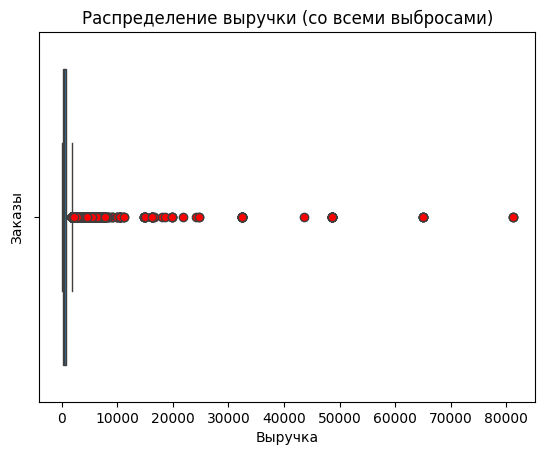

In [31]:
sns.boxplot(
    data=df,
    x='revenue_rub',
    flierprops={'markerfacecolor': 'red'}
)

plt.title('Распределение выручки (со всеми выбросами)')
plt.ylabel('Заказы')
plt.xlabel('Выручка')

На диаграмме много выбросов, и сама коробка (межквартильный размах) становится плохо различимой. Поэтому для визуального анализа дополнительно построена диаграмма с фильтрацией по 99-му перцентилю. Избавимся от части выбросов и посмотрим на диаграмму без них.

Text(0.5, 0, 'Выручка')

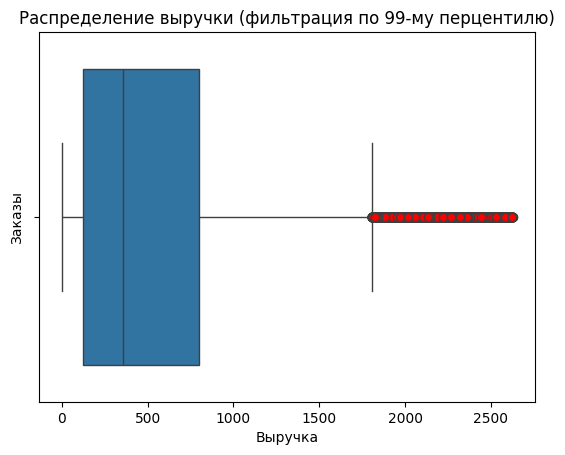

In [32]:
outliers = df['revenue_rub'].quantile(0.99)

sns.boxplot(
    data=df[(df['revenue_rub'] >= 0) & (df['revenue_rub'] < outliers)],
    x='revenue_rub',
    flierprops={'markerfacecolor': 'red'}
)

plt.title('Распределение выручки (фильтрация по 99-му перцентилю)')
plt.ylabel('Заказы')
plt.xlabel('Выручка')

Как мы видим из диаграммы размаха, распределение имеет правостороннюю (положительную) асимметрию. Медиана ближе к первому квартилю (Q1), значит, большинство значений сосредоточено в нижней части распределения, а редкие большие значения вытягивают правый хвост к Q3 и дальше. Межквартильный размах составляет около 650, половина значений лежит в диапазоне от 100 до 750. 

Рассмотрим показатель `tickets_count`.

Text(0.5, 0, 'Количество билетов')

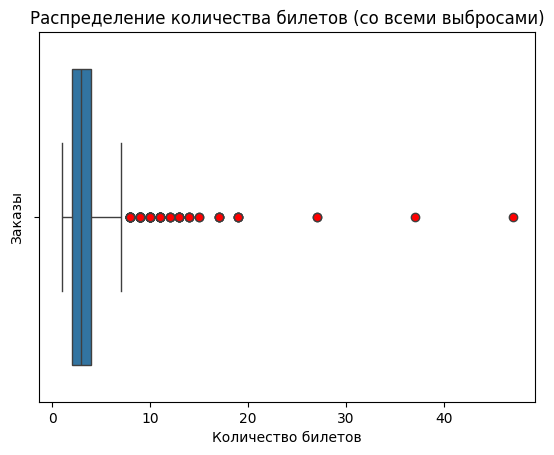

In [33]:
sns.boxplot(
    data=df,
    x='tickets_count',
    flierprops={'markerfacecolor': 'red'}
)

plt.title('Распределение количества билетов (со всеми выбросами)')
plt.ylabel('Заказы')
plt.xlabel('Количество билетов')

Рассмотрим диаграмму размаха с фильтрацией.

Text(0, 0.5, 'Заказы')

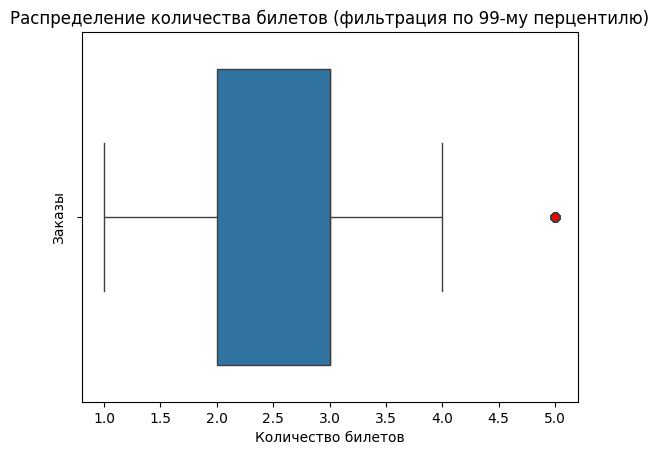

In [34]:
outliers = df['tickets_count'].quantile(0.99)

sns.boxplot(
    data=df[(df['tickets_count'] >= 0) & (df['tickets_count'] < outliers)],
    x='tickets_count',
    flierprops={'markerfacecolor': 'red'}
)

plt.title('Распределение количества билетов (фильтрация по 99-му перцентилю)')
plt.xlabel('Количество билетов')
plt.ylabel('Заказы')

Как мы видим, диаграмма показывает правостороннюю асимметрию, что видно из выбросов справа, которые формирует хвост. Медиана и Q3 равны 3. Это означает, что 25% заказов содержат ровно 3 билета, а значение 3 является самым типичным для покупателей. 

Рассмотрим показатель `days_since_prev`. Данный показатель имеет 7,55% пропусков, которые не будут отображаться на диаграмме.

Text(0, 0.5, 'Заказы')

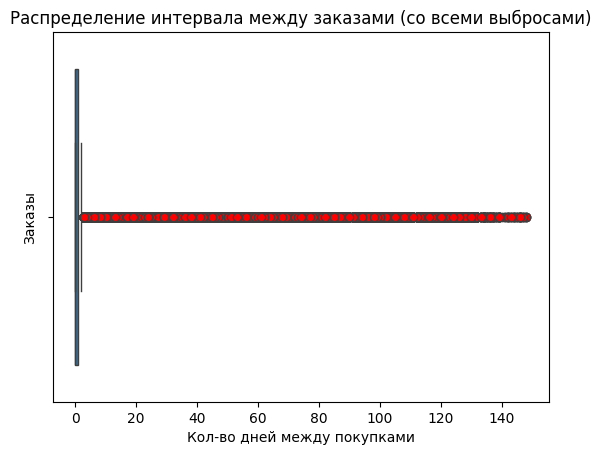

In [35]:
sns.boxplot(
    data=df,
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)
plt.title('Распределение интервала между заказами (со всеми выбросами)')
plt.xlabel('Кол-во дней между покупками')
plt.ylabel('Заказы')

Как и в предыдущих вариантах, стоит провести фильтрацию данных, чтобы построить различимую диаграмму.

Text(0, 0.5, 'Заказы')

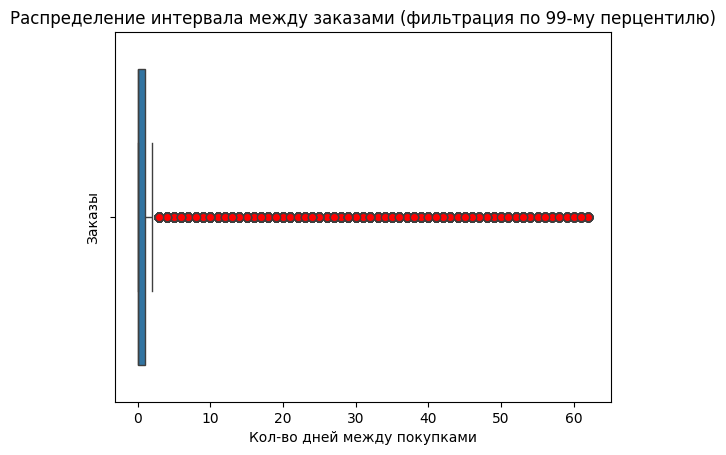

In [36]:
outliers = df['days_since_prev'].quantile(0.99)

sns.boxplot(
    data=df[(df['days_since_prev'] >= 0) & (df['days_since_prev'] < outliers)],
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)
plt.title('Распределение интервала между заказами (фильтрация по 99-му перцентилю)')
plt.xlabel('Кол-во дней между покупками')
plt.ylabel('Заказы')

Коробка размаха все равно плохо различима, поэтому принято решение увеличить фильтрацию до 95-го перцентиля.

Text(0, 0.5, 'Заказы')

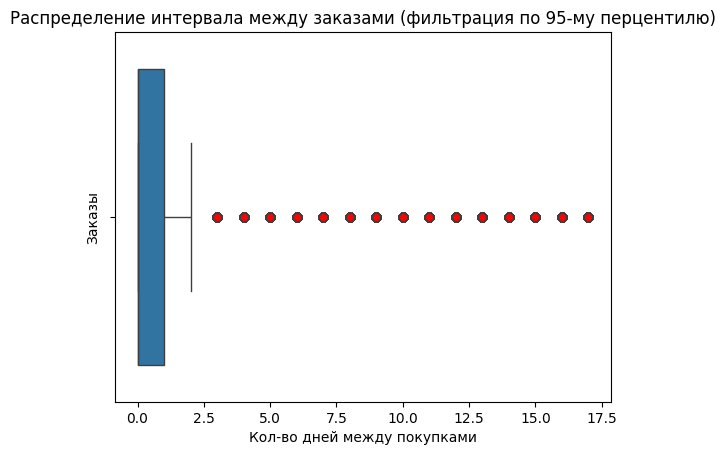

In [37]:
outliers = df['days_since_prev'].quantile(0.95)

sns.boxplot(
    data=df[df['days_since_prev'] < outliers],
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)
plt.title('Распределение интервала между заказами (фильтрация по 95-му перцентилю)')
plt.xlabel('Кол-во дней между покупками')
plt.ylabel('Заказы')

Из диаграммы видна правосторонняя асимметрия, также минимум и медиана равны 0. Это означает, что 50% повторных покупок имеют 0 дней разницы между предыдущим заказом. Из чего следует, что пользователи часто покупают билеты на разные события или докупают на одно и то же событие в один день.

- Строки с отрицательной и нулевой выручкой удалены как невалидные транзакции (возвраты и бесплатные билеты). 
- Экстремальные, но правдоподобные оставлены: чеки до 81 174 ₽, наборы до 57 билетов, интервалы до 148 дней физически возможны (окно наблюдения — 153 дня) и могут быть групповыми покупками или подарками.
- Фильтрация по 99-му (для интервалов — 95-му) перцентилю применяется только внутри графиков, в расчётах используются все данные.

---

### Промежуточный вывод

В результате предобработки данных были выполнены следующие действия:

__*Типы данных и память*__:
- Типы данных `device_type_canonical`, `currency_code` и `event_type_main` изменены на category для оптимизации памяти.
- Разрядность `tickets_count` и `days_since_prev` понижена до int8 и float32 соответственно.

__*Пропуски и дубликаты*__:

- Пропуски обнаружены только в days_since_prev (7,55%). Заполнять их не нужно, так как это исказит логику расчёта.
- Явных и неявных пропусков в остальных столбцах не обнаружено.
- Полных дубликатов и дубликатов по order_id + order_ts нет. Найдены и удалены неполные дубликаты: 41 группа, 44 строки (0.015%).

__*Новый столбец - `revenue_rub`*__: 

- Создан столбец revenue_rub — выручка, приведённая к рублю.
- Пропусков в revenue_rub нет (0). Для rub значения совпадают с revenue, для kzt — пересчитаны с делением на 100.

__*Выбросы и фильтрация*__:

- Обнаружены отрицательные значения revenue_rub (до -90.76) — возможно, возвраты.
- Обнаружены нулевые значения (мода = 0) — возможно, бесплатные билеты.
- Обнаружены экстремально большие значения (до 81 174 руб.) — это 1% выбросов.

Удалены невалидные транзакции (выручка ≤ 0) и неполные дубликаты. Экстремальные, но правдоподобные значения оставлены; фильтрация по перцентилям — только для графиков.

Также **половина повторных заказов сделана в тот же день** (0 дней разницы с предыдущим заказом), что говорит о склонности пользователей докупать билеты в один день.

***Дополнительный анализ категориальных признаков (по результатам SQL-EDA):***

Категориальные признаки были проверены на аномалии и малые выборки:
- device_type_canonical: преобладают mobile и desktop. Категории tablet, tv, other составляют менее 0.5% данных и были исключены на этапе формирования витрины.
- cinema_circuit: в 99% случаев имеет значение «нет», что делает этот признак неинформативным для анализа.
- event_type_main / event_type_description: выявлены категории с экстремально малой выборкой (например, рок-мюзикл — 1 заказ, подарок — 4 заказа). Они не удалялись, но их статистика учитывается с поправкой на малый размер выборки.
- service_name: распределение корректное, 36 уникальных значений, явных аномалий в названиях нет.


---
## Создание профиля пользователя

Профиль будет построен по таким признакам, как:
- дата первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетный партнёр, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия;
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.
- бинарный признак is_two — совершил ли пользователь 2 и более заказа;
- бинарный признак is_five — совершил ли пользователь 5 и более заказов.

Перед формированием профиля датасет отсортирован по user_id и order_ts, чтобы первая строка в группе действительно была первым заказом — иначе агрегации first_* возьмут произвольную запись.

In [38]:
df.sort_values(by=['user_id', 'order_ts'], ascending=True, inplace=True)

user_profile = df.groupby('user_id').agg(
    first_order_data = ('order_ts', 'min'),
    last_order_data = ('order_ts', 'max'),
    first_device_type = ('device_type_canonical', 'first'),
    first_region = ('region_name', 'first'),
    first_service_name = ('service_name', 'first'),
    first_event_type_main = ('event_type_main', 'first'),
    total_orders = ('order_id', 'count'),
    avg_revenue_rub = ('revenue_rub', 'mean'),
    avg_count_tickets = ('tickets_count', 'mean'),
    time_between_orders = ('days_since_prev', 'mean')
)


user_profile['is_two'] = user_profile['total_orders'] >= 2
user_profile['is_five'] = user_profile['total_orders'] >= 5

user_profile

,first_order_data,last_order_data,first_device_type,first_region,first_service_name,first_event_type_main,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders,is_two,is_five
user_id,,,,,,,,,,,,
0002849b70a3ce2,2024-08-20 16:08:03,2024-08-20 16:08:03,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,False,False
0005ca5e93f2cf4,2024-07-23 18:36:24,2024-10-06 13:56:02,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,75.000,True,False
000898990054619,2024-07-13 19:40:48,2024-10-23 15:12:00,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,51.000,True,False
00096d1f542ab2b,2024-08-15 16:48:48,2024-08-15 16:48:48,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,False,False
000a55a418c128c,2024-09-29 19:39:12,2024-10-15 10:29:04,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,16.000,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
fff13b79bd47d7c,2024-07-16 22:17:10,2024-10-31 18:31:52,mobile,Каменевский регион,Мой билет,другое,9,688.043333,2.555556,13.375,True,True
fff32fc9ad0f9f6,2024-08-15 14:36:28,2024-10-28 23:40:38,desktop,Каменевский регион,Билеты без проблем,стендап,2,850.995000,2.500000,74.000,True,False
fffcd3dde79eb2c,2024-06-20 19:57:25,2024-10-30 13:37:43,desktop,Каменевский регион,Билеты без проблем,концерты,33,557.908485,2.787879,4.125,True,True


In [39]:
# Проверка 
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21779 entries, 0002849b70a3ce2 to ffff00725179321
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   first_order_data       21779 non-null  datetime64[us]
 1   last_order_data        21779 non-null  datetime64[us]
 2   first_device_type      21779 non-null  category      
 3   first_region           21779 non-null  str           
 4   first_service_name     21779 non-null  str           
 5   first_event_type_main  21779 non-null  category      
 6   total_orders           21779 non-null  int64         
 7   avg_revenue_rub        21779 non-null  float64       
 8   avg_count_tickets      21779 non-null  float64       
 9   time_between_orders    13495 non-null  float32       
 10  is_two                 21779 non-null  bool          
 11  is_five                21779 non-null  bool          
dtypes: bool(2), category(2), datetime64[us](2), float32(

- Для пользователей с одним заказом среднее время между заказами не определено (NaN).
- Разница между общим числом уникальных пользователей в исходной таблице (22 000) и в выгрузке (21 933) обусловлена фильтрацией по устройству и исключением категории «фильм». После очистки осталось 21 779 пользователей, после удаления аномального — 21 778.

---
Прежде чем проводить исследовательский анализ данных, стоит изучить сформированный профиль.

In [40]:
user_profile.describe(percentiles=[0.01,0.5, 0.99])

,first_order_data,last_order_data,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders
count,21779,21779,21779.000000,21779.000000,21779.000000,13495.000000
mean,2024-08-10 19:24:49.283805,2024-09-19 04:24:07.719867,13.070481,581.786481,2.758935,15.874021
min,2024-06-01 00:00:42,2024-06-01 01:29:40,1.000000,0.070000,1.000000,0.000000
1%,2024-06-01 13:12:52.020000,2024-06-04 18:27:29.280000,1.000000,12.737486,1.000000,0.000000
50%,2024-08-09 14:55:00,2024-10-03 19:40:48,2.000000,483.584444,2.772727,8.062500
99%,2024-10-30 21:59:33.300000,2024-10-31 22:32:33.740000,152.000000,2285.900328,5.000000,113.000000
max,2024-10-31 23:55:27,2024-10-31 23:59:54,10057.000000,16738.696667,12.000000,148.000000
std,NaN,NaN,120.554799,557.962424,0.921925,22.293419


Исходя из описания профилей пользователей, существует пользователь с 10 057 заказами при медиане 2. **Такое аномальное значение стоит удалить для исключения статистических искажений.**

In [41]:
client_index = user_profile[user_profile['total_orders'] == user_profile['total_orders'].max()].index
user_profile.drop(client_index, inplace=True)
df = df[~df['user_id'].isin(client_index)] 

print(f'Количество строк после удаления аномалии: {user_profile.shape[0]}')
print(f'Заказов в df после удаления аномалии: {df.shape[0]}')

Количество строк после удаления аномалии: 21778
Заказов в df после удаления аномалии: 274605


In [42]:
user_profile.describe(percentiles=[0.01, 0.5, 0.99])

,first_order_data,last_order_data,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders
count,21778,21778,21778.000000,21778.000000,21778.000000,13494.000000
mean,2024-08-10 19:29:30.153549,2024-09-19 04:21:17.940261,12.609285,581.788699,2.758930,15.875196
min,2024-06-01 00:00:42,2024-06-01 01:29:40,1.000000,0.070000,1.000000,0.000000
1%,2024-06-01 13:12:57.850000,2024-06-04 18:27:25.520000,1.000000,12.737371,1.000000,0.000000
50%,2024-08-09 14:59:53,2024-10-03 19:37:12.500000,2.000000,483.582222,2.772542,8.066964
99%,2024-10-30 21:59:37.450000,2024-10-31 22:32:29.230000,150.460000,2285.938400,5.000000,113.000000
max,2024-10-31 23:55:27,2024-10-31 23:59:54,4320.000000,16738.696667,12.000000,148.000000
std,NaN,NaN,99.506181,557.975139,0.921946,22.293827


Видим, что все равно присутствует аномально большое значение в колонке `total_orders`. Рассмотрим данные, которые больше 99-перцентеля:

In [43]:
one_percentage_users = user_profile[user_profile['total_orders'] > user_profile['total_orders'].quantile(0.99)]
one_percentage_users.describe()

,first_order_data,last_order_data,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders
count,218,218,218.000000,218.000000,218.000000,218.000000
mean,2024-06-03 04:58:44.711009,2024-10-31 14:57:48.944954,623.600917,562.848294,2.744587,0.468480
min,2024-06-01 00:00:42,2024-10-22 14:51:08,152.000000,69.748451,2.031250,0.033573
25%,2024-06-01 11:01:39,2024-10-31 15:54:11,212.000000,514.618195,2.665847,0.232909
50%,2024-06-01 18:17:53.500000,2024-10-31 21:42:56,314.000000,563.750337,2.744153,0.461404
75%,2024-06-02 21:41:44.500000,2024-10-31 23:01:03.250000,630.250000,614.269780,2.828540,0.696686
max,2024-09-03 11:02:57,2024-10-31 23:58:55,4320.000000,1910.725097,3.598456,0.993378
std,NaN,NaN,771.549540,140.351534,0.169025,0.278625


Удалять 1% пользователей нецелесообразно, так как тогда, возможно, удалятся и самые лояльные пользователи. **Проверим, какую часть от заказов составляет 1% пользователей по рассчитанным перцентилям.**

In [44]:
for quant, orders_sum in one_percentage_users['total_orders'].quantile([0, 0.25, 0.5, 0.75, 0.99, 1]).items():
    loyal_users = one_percentage_users[one_percentage_users['total_orders'] >= orders_sum]['total_orders']
    result = loyal_users.sum()
    print(f'Количество заказов у {100 - quant * 100}%: {result} \n Пользователей: {len(loyal_users)} \n Составляет {round(result * 100 / df.shape[0],1)}% датасета \n')

Количество заказов у 100.0%: 135945 
 Пользователей: 218 
 Составляет 49.5% датасета 

Количество заказов у 75.0%: 126466 
 Пользователей: 164 
 Составляет 46.1% датасета 

Количество заказов у 50.0%: 112346 
 Пользователей: 109 
 Составляет 40.9% датасета 

Количество заказов у 25.0%: 86768 
 Пользователей: 55 
 Составляет 31.6% датасета 

Количество заказов у 1.0%: 11982 
 Пользователей: 3 
 Составляет 4.4% датасета 

Количество заказов у 0.0%: 4320 
 Пользователей: 1 
 Составляет 1.6% датасета 



Как мы видим 135 945 заказов это 49.5% процентов от текущего очищенного датасета. Удалять весь 1% точно нельзя, так как вместе с ними уйдёт около половины всех заказов. Рассмотрим топ 10 клиентов по количеству заказов.

In [45]:
one_percentage_users['total_orders'].sort_values(ascending=False).head(10)

user_id
18e9aead0a393e7    4320
8187dac4be757a0    3921
3ee7dc2e115847f    3741
7eb4fc207ecc10f    3629
1c2a2133e1df1b4    3505
4ec8f6429431987    3375
ad2dc32364ed948    3230
b54dd0cd81121fc    3111
cdbc02c6ad8087a    3056
02ea4583333f064    2939
Name: total_orders, dtype: int64

Разница между соседними аккаунтами — 55–399 заказов, разрыва нет: это непрерывный хвост, а не выбросы. Удалённый аккаунт с 10 057 заказами отличался пропастью в 5 737 заказов от следующего, поэтому был аномалией. Удаление по произвольному порогу будет считаться некорректным, а удаление группы стоит 49.5% заказов. **Принято решение оставить такие аккаунты.**

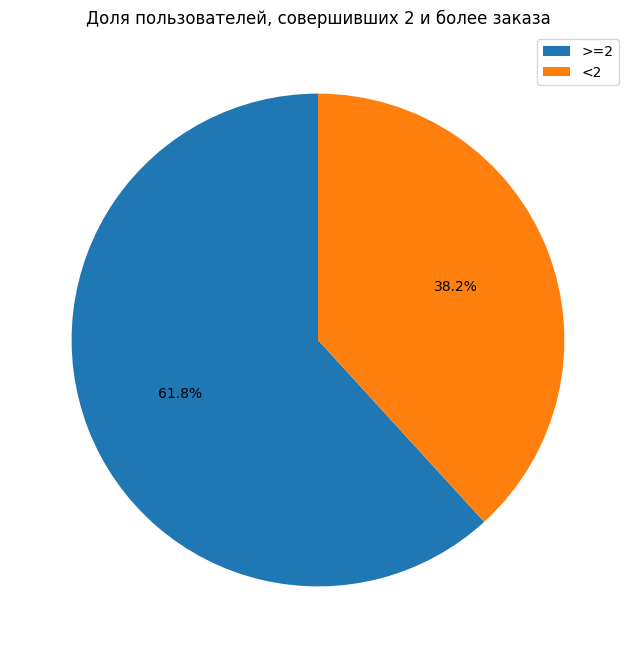

In [46]:
is_two_count = user_profile['is_two'].sum()

size = [
    is_two_count,
    user_profile.shape[0] - is_two_count
]
plt.figure(figsize=(12, 8))

plt.pie(
    size,
    startangle=90, 
    autopct='%1.1f%%',
)

plt.title('Доля пользователей, совершивших 2 и более заказа')
plt.legend(['>=2', '<2'])

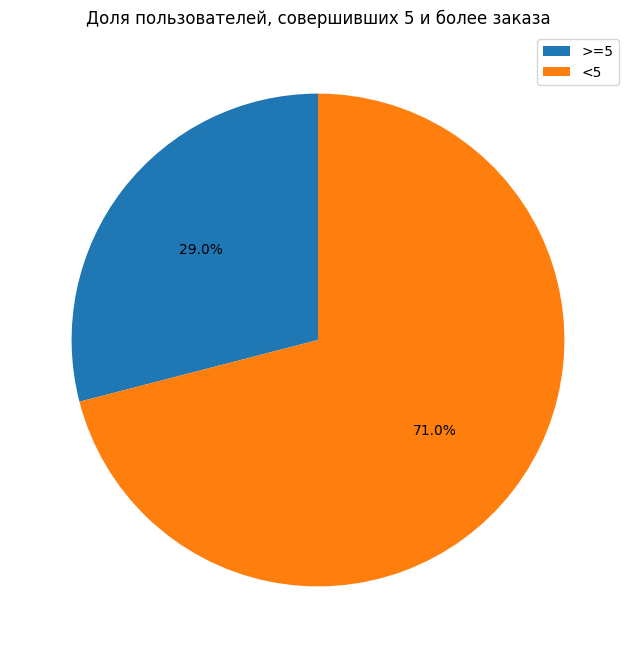

In [47]:
is_five_count = user_profile['is_five'].sum()

size = [
    is_five_count,
    user_profile.shape[0] - is_five_count
]

plt.figure(figsize=(12, 8))

plt.pie(
    size,
    startangle=90, 
    autopct='%1.1f%%',
)

plt.title('Доля пользователей, совершивших 5 и более заказа')
plt.legend(['>=5', '<5'])

---
### Промежуточный вывод

***В ходе анализа профилей пользователей было выявлено:***
- Общее число пользователей: 21 778.
- Доля пользователей с 2+ заказами: 61.8%
- Доля пользователей с 5+ заказами: 29.2%
- Доля пользователей с 1 заказом: 38.2%

Примечание: В категорию пользователей с 2+ заказами включены пользователи с 5+ заказами.

***По столбцу `avg_revenue_rub` определено:***
- Среднее: 582 руб.
- Медиана (50%): 484 руб.
- Максимум: 16 739 руб.
- 99-й перцентиль: 2 286 руб.
- Стандартное отклонение: 558 руб.

Стандартное отклонение почти равно среднему, что свидетельствует о сильном разбросе, поэтому разница между максимумом и 99-м перцентилем составляет 14 453 руб.

***По столбцу `total_orders` определено:***
- Среднее: 12.61
- Медиана: 2.
- 99-й перцентиль: 150
- Стандартное отклонение: 99.5.



***По столбцу `avg_count_tickets` определено:***
- Среднее: 2.77.
- Медиана (50%): 2.76.
- 99-й перцентиль: 5.
- Максимум: 12.
- Стандартное отклонение: 0.92.

Медиана и среднее близки (2.77 и 2.76   ), сильного смещения распределения нет.

***По столбцу `time_between_orders` определено:***
- Среднее: 15.9 дней.
- Медиана (50%): 8 дней.
- 99-й перцентиль: 113 дней.
- Максимум: 148 дней.
- Стандартное отклонение: 22.3 дня.
- Пропуски: 8 284 пользователя.

Данные пропуски корректны. Пропущенное значение указывает, что пользователь сделал всего одну покупку.

### Итог по очистке от аномалий:
Из датасета были удалены невалидные транзакции и технические выбросы:
- Неполные дубликаты: 44 строки (0.02% от исходных данных).
- Невалидная выручка: 5 905 строк (2.03%) — возвраты средств и бесплатные билеты.
- Аномальный пользователь: 10 057 строк (3.46%) — пользователь с экстремальным числом заказов, искажающий статистику среднего.

**Суммарные потери**: удалено 16 006 строк из 290 611 (5.51%). Пользователей: было 21 933 стало 21 778 (154 состояли только из невалидных транзакций, 1 — аномальный).
Потери некритичны, качество данных для построения профиля и дальнейшего анализа существенно повышено.

Около 1% аккаунтов генерирует примерно половину всех заказов. У каждого из них средний интервал между заказами меньше суток, а период активности охватывает почти всё окно наблюдения. Такой режим покупок нехарактерен для частных покупателей и может указывать на агрегаторов или автоматизированные заказы; проверка их природы требует данных со стороны бизнеса. Аккаунты сохранены, поэтому среднее число заказов на пользователя (12.6) не репрезентативно — типичное значение описывает медиана (2 заказа).

---
## Исследовательский анализ данных

### Исследование признаков первого заказа и их связи с возвращением на платформу
---
В рамках исследования мы проверим **две продуктовые гипотезы**:

- ***Гипотеза 1:*** Тип мероприятия влияет на вероятность возврата: пользователи, начавшие со спортивных мероприятий, совершают повторный заказ чаще, чем те, кто начал с концертов.

- ***Гипотеза 2:*** В регионах с наибольшим числом пользователей доля повторных заказов выше, чем в менее активных регионах.

Проведем сегментацию пользователей:
- по типу их первого мероприятия;
- по типу устройства, с которого совершена первая покупка;
- по региону проведения мероприятия из первого заказа;
- по билетному оператору, продавшему билеты на первый заказ.

***Сегментация по типу первого мероприятия:***

Text(0.5, 0, 'Доля в %')

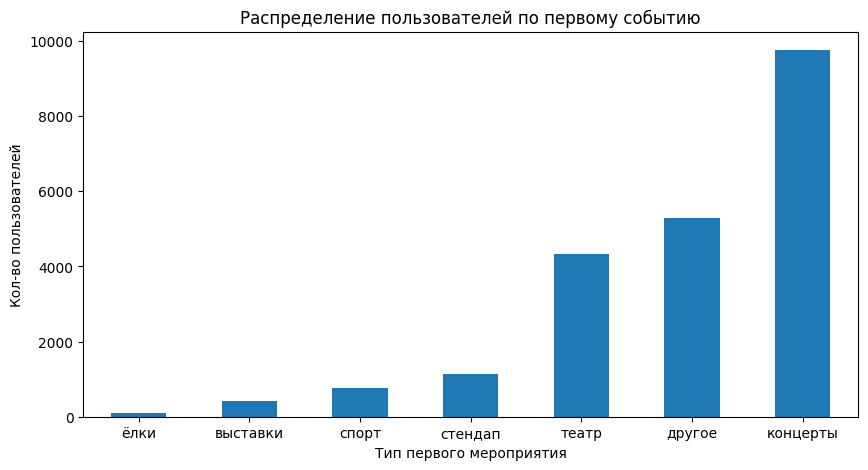

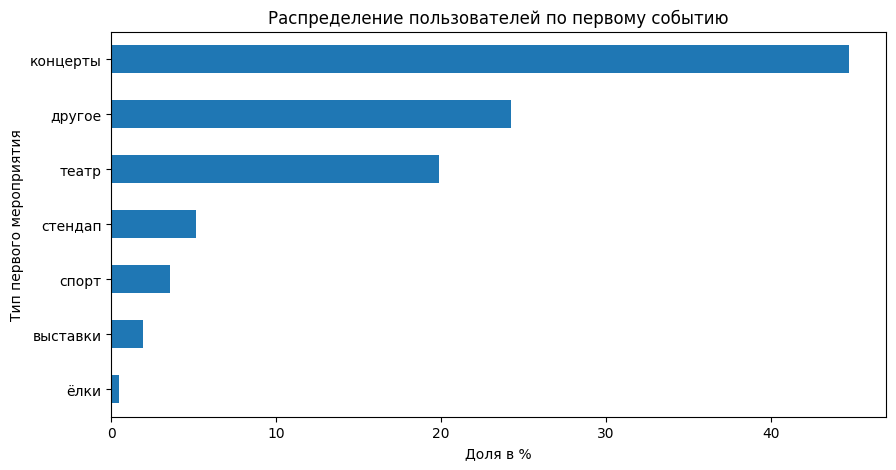

In [48]:
# сегментация пользователей по их первому мероприятию
user_grouped = user_profile.groupby('first_event_type_main').size().sort_values()

user_grouped.plot(
    kind='bar',
    title='Распределение пользователей по первому событию',
    ylabel='Кол-во пользователей',
    xlabel='Тип первого мероприятия',
    rot=0,
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh'
    )
plt.title('Распределение пользователей по первому событию')
plt.ylabel('Тип первого мероприятия')
plt.xlabel('Доля в %')

In [49]:
user_share

first_event_type_main
ёлки         0.45
выставки     1.91
спорт        3.55
стендап      5.17
театр       19.89
другое      24.27
концерты    44.77
dtype: float64

Распределение сильно неравномерное, явные точки входа:
- концерты - 44% 
- другое - 25%
- театры - 20%

Меньше всего пользователей выбрали в качестве первого своего мероприятия в категориях:
- ёлки - 0.4%
- выставки - 1.9%

Найдем в каждом сегменте долю пользователей, которые совершили 2 и более заказов.

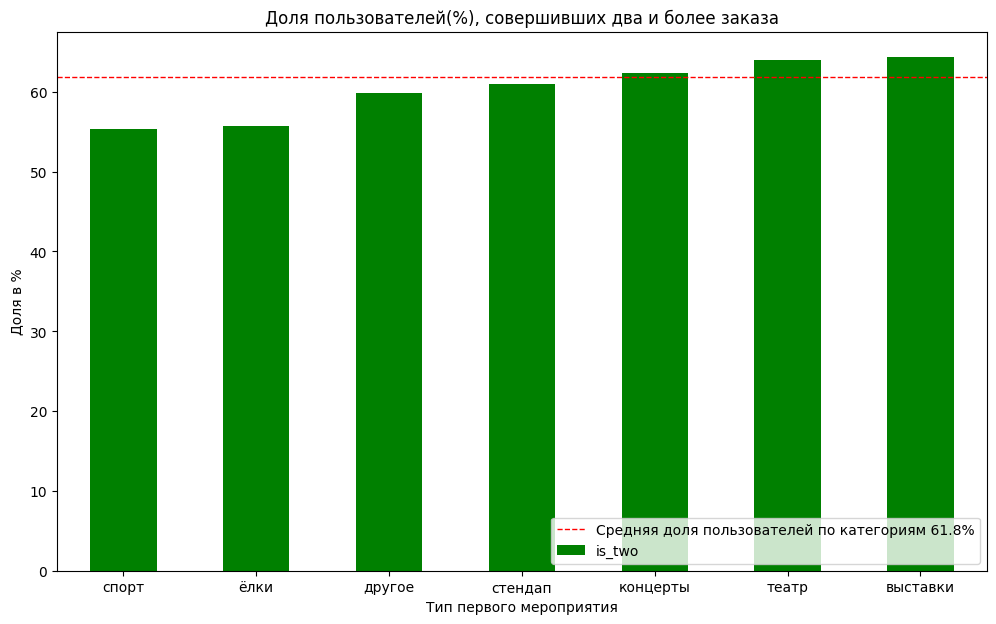

In [50]:
user_grouped_share = user_profile.groupby('first_event_type_main')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='bar',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Доля в %',
    xlabel='Тип первого мероприятия',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axhline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по категориям {mean_share}%')

plt.legend(loc='lower right')

In [51]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_event_type_main,,,
концерты,62.4,9749,6083.0
другое,59.9,5285,3166.0
театр,64.0,4332,2772.0
стендап,61.0,1126,687.0
спорт,55.3,774,428.0
выставки,64.3,415,267.0
ёлки,55.7,97,54.0


Доли распределены более равномерно, лидерами являются:
- `выставки` - 64% при **415** пользователей
- `театр` - 64% при **4332**
- `концерты` - 62.4% - **9749**

Категория `выставки` лидирует по доле вернувшихся пользователей, но по абсолютному значению вернувшихся пользователей первое место занимает категория `концерты`:6083, а выставки всего 267.
Средняя доля вернувшихся по всей выборке составляет 61.8%. Успешными точками входа (доля выше средней) являются `выставки`, `театр` и `концерты`. Категории стендап, другое, спорт и ёлки — ниже среднего.

***Продолжим сегментацию по типу устройства:***

Text(0.5, 1.0, 'Распределение пользователей по типу устройства')

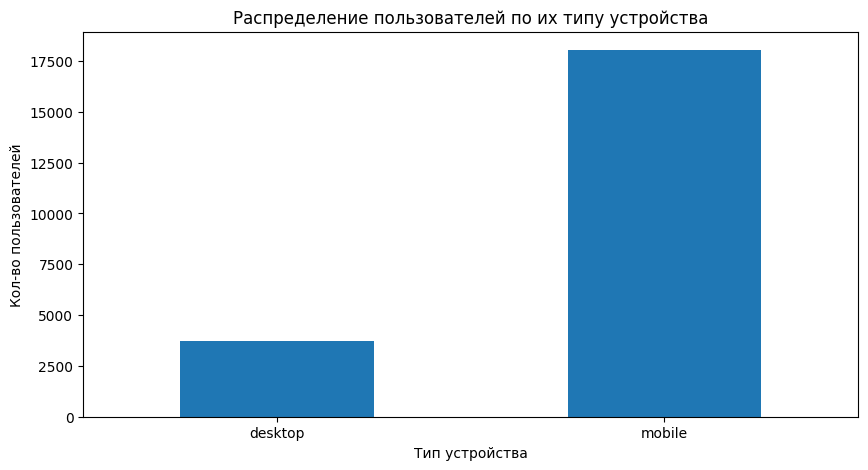

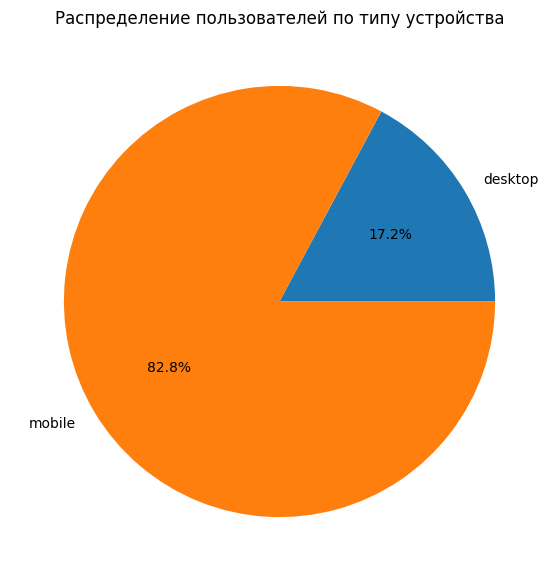

In [52]:
# сегментация пользователей по типу устройства, с которого совершена первая покупка
user_grouped = user_profile.groupby('first_device_type').size().sort_values()

user_grouped.plot(
    kind='bar',
    title='Распределение пользователей по их типу устройства',
    ylabel='Кол-во пользователей',
    xlabel='Тип устройства',
    rot=0,
    figsize=(10,5)
)

plt.figure(figsize=(7,7))

user_grouped.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Распределение пользователей по типу устройства')


Распределение сильно неравномерное, явная точка входа - тип устройства `mobile`. Пользователей с данным типом почти в 5 раз больше, чем людей использовавших компьютер для первого заказа.

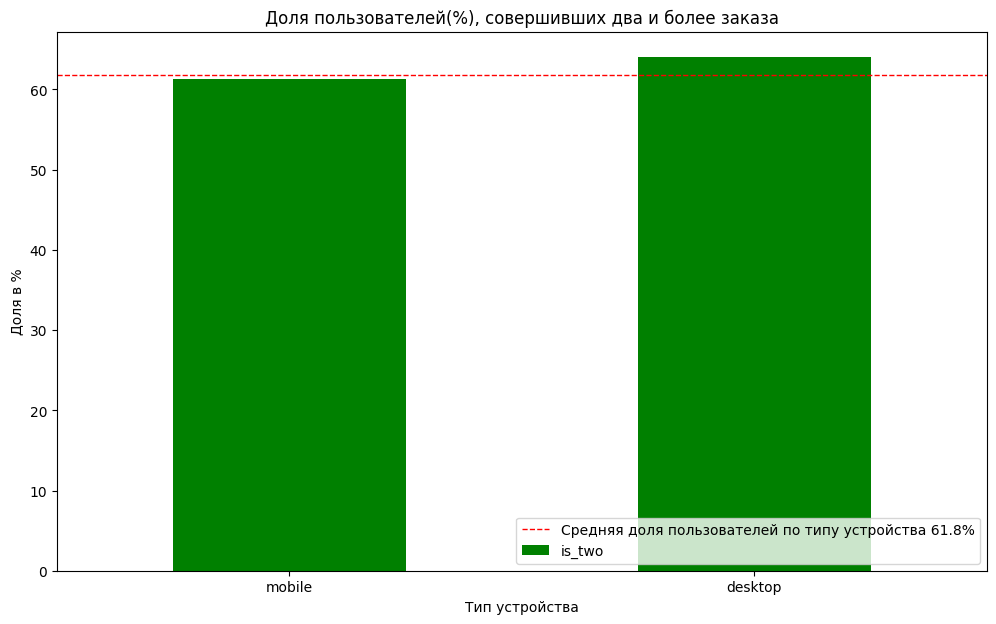

In [53]:
user_grouped_share = user_profile.groupby('first_device_type')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='bar',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Доля в %',
    xlabel='Тип устройства',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axhline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по типу устройства {mean_share}%')

plt.legend(loc='lower right')

In [54]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_device_type,,,
mobile,61.3,18038,11057.0
desktop,64.0,3740,2394.0


Доля вернувшихся пользователей с desktop (64.0%) немного выше средней (61.8%), а с mobile (61.3%) — чуть ниже. Однако абсолютным лидером по числу вернувшихся пользователей является mobile (11 057 против 2 394). Это означает, что хотя конверсия в повторный заказ на компьютере выше, но  **основной объём лояльных и постоянных клиентов приходит с мобильных устройств**.

***Проведем сегментацию пользователей по региону, в котором был совершен их первый заказ***

In [55]:
# сегментация пользователей по региону, в котором был совершен первый заказ
user_grouped = user_profile.groupby('first_region').size().sort_values()
user_grouped

first_region
Верхозёрский край              1
Сосноводолинская область       1
Яснопольский округ             1
Залесский край                 2
Светолесский край              2
                            ... 
Малиновоярский округ         538
Озернинский край             682
Широковская область         1254
Североярская область        3814
Каменевский регион          7094
Length: 81, dtype: int64

Как мы видим, всего 81 регион, где были совершены заказы. Из-за большого количества регионов распределение сложно будет отобразить, поэтому стоит провести фильтрацию и исключить некоторые регионы из визуализации. Для распределения хватит 10 самых крупных по числу пользователей регионов.

In [56]:
user_grouped.describe()

count      81.000000
mean      268.864198
std       892.103088
min         1.000000
25%        22.000000
50%        52.000000
75%       216.000000
max      7094.000000
dtype: float64

Из описания серии видно, что распределение крайне неравномерное, при медианном значении 52 и среднем 269, можно сказать, что в данных имеются выбросы, об этом также говорит стандартное отклонение 892 (пользователей).

In [57]:
user_grouped = user_grouped.iloc[-10:]
print('Топ-10 регионов по числу пользователей')
user_grouped

Топ-10 регионов по числу пользователей


first_region
Яблоневская область      419
Речиновская область      447
Травяная область         467
Светополянский округ     472
Шанырский регион         473
Малиновоярский округ     538
Озернинский край         682
Широковская область     1254
Североярская область    3814
Каменевский регион      7094
dtype: int64

<Axes: title={'center': 'Распределение пользователей по топ 10 регионам'}, xlabel='Доля в %', ylabel='Регион'>

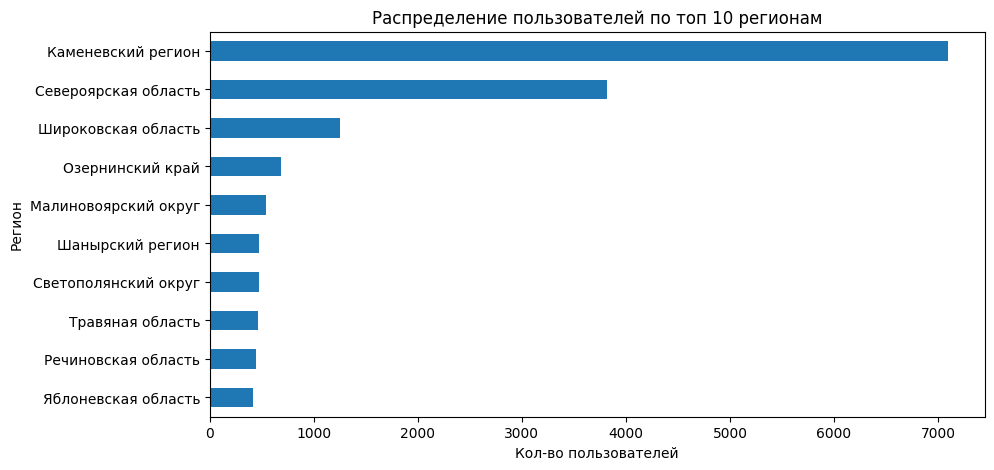

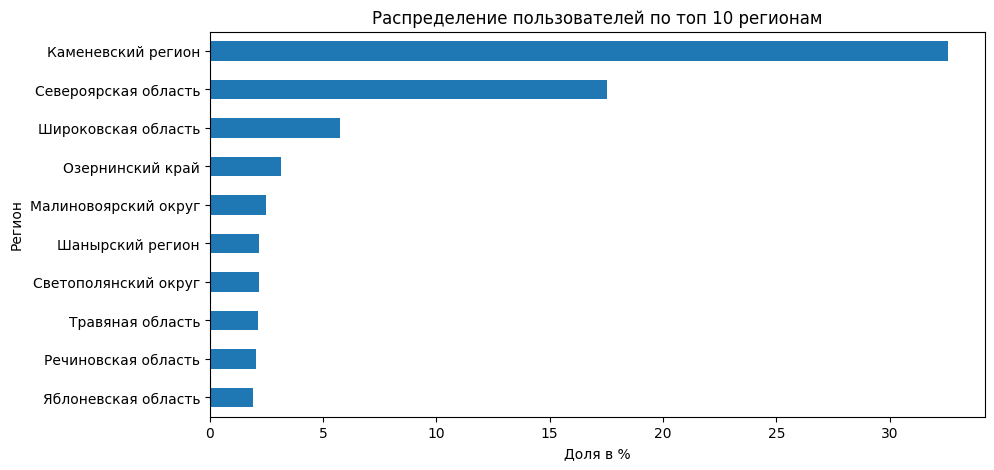

In [58]:
# сегментация пользователей по региону, из которого был совершен первый заказ
user_grouped.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 регионам',
    ylabel='Регион',
    xlabel='Кол-во пользователей',
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 регионам',
    ylabel='Регион',
    xlabel='Доля в %',
    figsize=(10,5)
)

In [59]:
print(f'Топ-10 регионов покрывают {round(user_share.sum(),2)}% всех пользователей (остальные 71 регион: {round(100 - user_share.sum(),2)}%)')

Топ-10 регионов покрывают 71.89% всех пользователей (остальные 71 регион: 28.11%)


Точка входа - сегмент `Каменевский регион`, кол-во пользователей в данном регионе составляет 32.6% (7094 пользователя). Потом идет `Североярская область` - 17.5% (3814) и `Широковская область` - 5.8% (1254). 

Если взять топ-10 регионов по доле возвратов, в них попадут регионы с 1–2 пользователями, где доля в 100% — это статистический шум. Поэтому для корректного анализа следует посчитать для 10 самых больших регионов по пользователям долю возвратов.

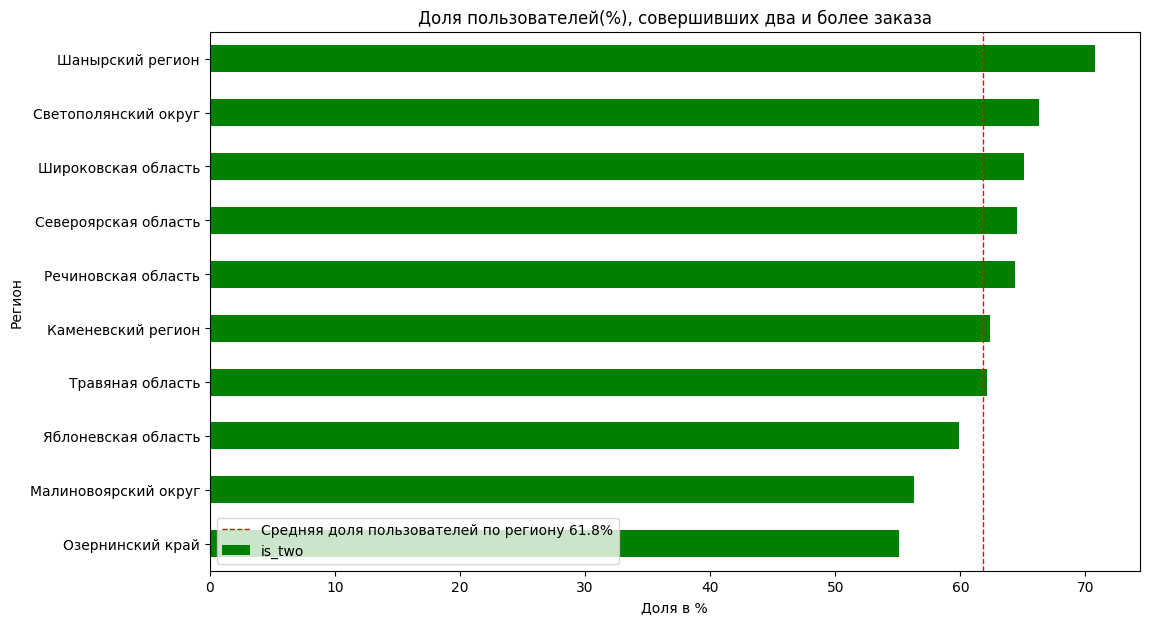

In [60]:
# Возьмем 10 крупнейших по числу пользователей регионов 
mask_for_10_regions = user_profile['first_region'].isin(user_share.index)
user_grouped_share = user_profile[mask_for_10_regions].groupby('first_region')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='barh',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Регион',
    xlabel='Доля в %',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axvline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по региону {mean_share}%')

plt.legend(loc='lower left')


In [61]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_region,,,
Каменевский регион,62.4,7094,4427.0
Североярская область,64.5,3814,2460.0
Широковская область,65.1,1254,816.0
Озернинский край,55.1,682,376.0
Малиновоярский округ,56.3,538,303.0
Шанырский регион,70.8,473,335.0
Светополянский округ,66.3,472,313.0
Травяная область,62.1,467,290.0
Речиновская область,64.4,447,288.0


Среди 10 крупнейших регионов (на которые приходится 71.9% всех пользователей) есть как успешные точки входа, так и проблемные зоны.
- Лидер по доле возвратов — Шанырский регион (70.8%). Однако это сравнительно небольшой сегмент (473 пользователя)
- Абсолютный лидер по числу лояльных клиентов — Каменевский регион. Его доля возвратов (62.4%) чуть выше средней, но за счёт огромного размера (7094 пользователей) именно этот регион приносит 4427 вернувшихся клиента — больше, чем любой другой.

**Проблемные регионы**: Озернинский край (55.1%) и Малиновоярский округ (56.3%) — в них доля возвратов заметно ниже средней (61.8%). Это зоны, которые требуют дополнительного внимания маркетинга.



***Рассмотрим распределение пользователей по билетному оператору.***

In [62]:
# сегментация пользователей по билетному оператору
user_grouped = user_profile.groupby('first_service_name').size().sort_values()
user_grouped.describe()

count      34.000000
mean      640.529412
std      1159.877455
min         1.000000
25%        25.500000
50%       132.000000
75%       440.250000
max      5013.000000
dtype: float64

Распределение не является равномерным, есть аномально высокие значения. Кол-во в 34 оператора сложно будет визуализировать, для этого стоит провести фильтрацию и оставить только 10 самых крупных билетных операторов.

In [63]:
user_grouped = user_grouped.iloc[-10:]
print('Топ-10 операторов по числу пользователей')
user_grouped

Топ-10 операторов по числу пользователей


first_service_name
Дом культуры           357
Край билетов           468
Прачечная              595
Лучшие билеты         1185
Весь в билетах        1327
Облачко               2214
Билеты в руки         2576
Лови билет!           2845
Мой билет             3048
Билеты без проблем    5013
dtype: int64

<Axes: title={'center': 'Распределение пользователей по топ 10 билетным операторам'}, xlabel='Доля в %', ylabel='Оператор'>

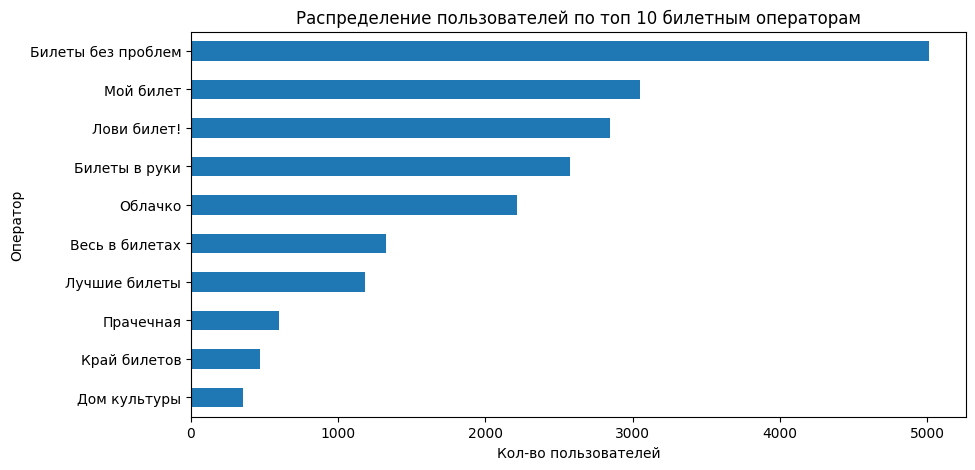

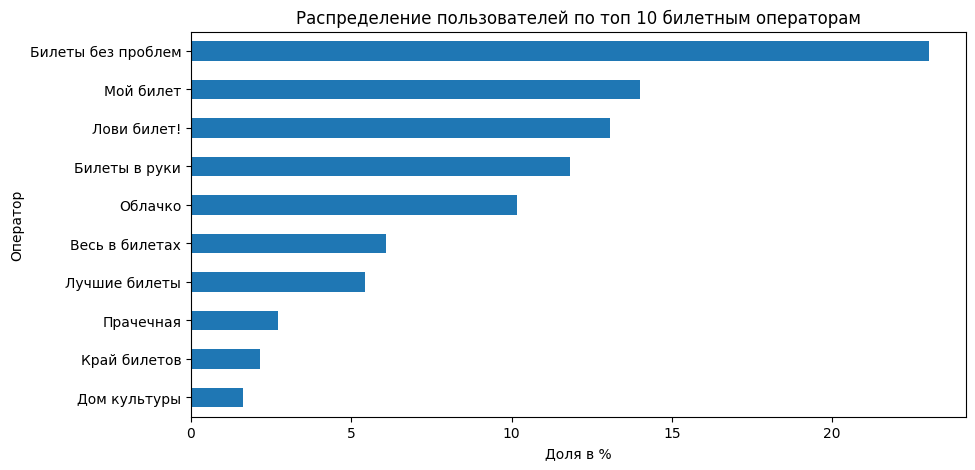

In [64]:
user_grouped.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 билетным операторам',
    ylabel='Оператор',
    xlabel='Кол-во пользователей',
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 билетным операторам',
    ylabel='Оператор',
    xlabel='Доля в %',
    figsize=(10,5)
)

In [65]:
print(f'Топ-10 операторов покрывают {round(user_share.sum(),2)}% пользователей (остальные 24 — {round(100 - user_share.sum(),2)}%)')

Топ-10 операторов покрывают 90.13% пользователей (остальные 24 — 9.87%)


Наибольшие сегменты:
- Лови билет! - 13% (2845 пользователей)
- Мой билет - 14% (3048)
- Билеты без проблем - 23% (5013)

<!-- Если взять топ-10 билетных операторов по доле возвратов, в нем может быть также как и в ситуации с регионами - **статистический шум**, поэтому для корректного анализа следует посчитать для 10 самых больших по пользователям операторов долю возвратов. -->

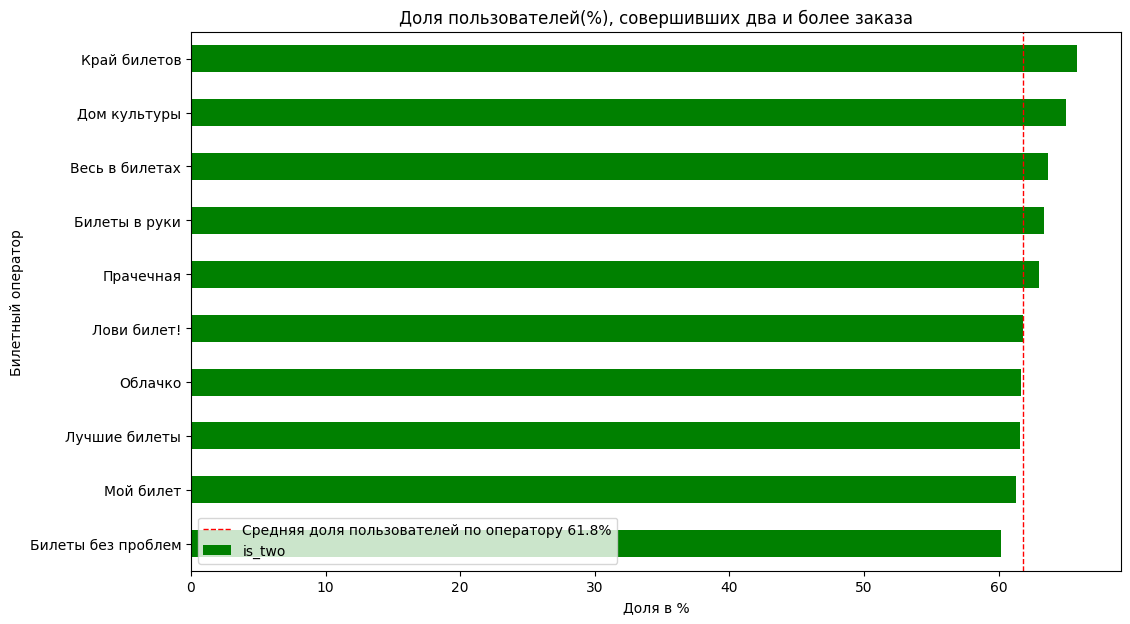

In [66]:
# Возьмем 10 крупнейших по числу пользователей билетных операторов
mask_for_10_operators = user_profile['first_service_name'].isin(user_share.index)
user_grouped_share = user_profile[mask_for_10_operators].groupby('first_service_name')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='barh',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа', 
    ylabel='Билетный оператор',
    xlabel='Доля в %',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axvline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по оператору {mean_share}%')

plt.legend(loc='lower left')


In [67]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_service_name,,,
Билеты без проблем,60.2,5013,3018.0
Мой билет,61.3,3048,1868.0
Лови билет!,61.8,2845,1758.0
Билеты в руки,63.4,2576,1633.0
Облачко,61.7,2214,1366.0
Весь в билетах,63.7,1327,845.0
Лучшие билеты,61.6,1185,730.0
Прачечная,63.0,595,375.0
Край билетов,65.8,468,308.0


Среди 10 крупнейших операторов (на которых приходится 90.1%):
- Лидер по доле возвратов — Край билетов (65.8%). Это выше средней доли по выборке (61.8%). Однако по абсолютному числу вернувшихся клиентов он занимает лишь предпоследнее место (308 человека), так как его общая аудитория мала (468 пользователя).
- Абсолютный лидер по объёму — Билеты без проблем. У него самая большая аудитория (5013 пользователя) и самое большое число вернувшихся (3018 человека). Но по доле возвратов он замыкает десятку (60.2%), находясь чуть ниже среднего уровня.
- Остальные крупные операторы (Мой билет, Лови билет!, Билеты в руки) показывают стабильную долю возвратов в диапазоне 61.3–63.4%, близкую к среднему значению.

Проверка выдвинутых гипотез:
1) ***Гипотеза 1 - Пользователи, начавшие со спорта, возвращаются чаще, чем начавшие с концертов***: гипотеза опровергнута. Доля вернувшихся со спорта составляет 55.3%, а с концертов — 62.4%. Спорт оказался одним из самых слабых сегментов.

2) ***Гипотеза 2 - В регионах с наибольшим числом пользователей доля повторных заказов выше, чем в менее активных:*** гипотеза подтверждается частично. В трёх крупнейших регионах (Каменевский, Североярская, Широковская) доля возвратов (62.4%, 64.5% и 65.1%) держится выше средней по выборке (61.8%). Однако абсолютным лидером по доле стал Шанырский регион (70.8%), который не входит в топ-5 по количеству пользователей. При этом некоторые небольшие регионы показывают результат ниже среднего, например, Яблоневская область.

---
### Промежуточный вывод

В ходе исследовательского анализа признаков первого заказа и их связи с возвращением на платформу было выявлено:

1. **Средняя доля возвратов** (средняя по выборке): **61.8%.**

2. ***Самые массовые сегменты:***
- _По типу события_: Концерты (44%), Другое (25%), Театр (20%).
- _По устройству_: Mobile (18 038 чел. — 83% всех пользователей).
- _По региону_: Каменевский регион (7094 чел. — 32.6%), Североярская обл. (3814 чел. — 17,5%). Топ-10 регионов покрывают 71.9% пользователей.
- _По оператору_: Билеты без проблем (5013 чел.), Мой билет (3048), Лови билет! (2845). Топ-10 операторов покрывают 90.1% пользователей.

3. ***Лидеры по удержанию*** (доля возвратов выше 61.8%):
- _По событию_: Выставки (64.3%), Театр (64%), Концерты (62.4%).
- _По устройству_: desktop (64.0%).
- _По региону_: Шанырский (70.8%), Светополянский (66.3%), Широковская обл. (65.1%).
- _По оператору_: Край билетов (65.8%), Дом культуры (65%).

4. ***Аутсайдеры по удержанию*** (доля возвратов ниже 61.8%):
- _По событию_: Спорт (55.3%), Ёлки (55.7%).
- _По устройству_: Mobile (61.3%).
- _По региону_: Озернинский край (55.1%), Малиновоярский округ (56.3%).
- _По оператору_: Билеты без проблем (60.2%), Мой билет (61.3%).

Несмотря на то, что у Desktop доля возвратов выше, абсолютное число вернувшихся пользователей составляет 2394, а у Mobile — 11 057, потому что мобильных пользователей почти в 5 раз больше. То же самое с событиями: у Выставок доля 64%, но вернувшихся всего 267, а у Концертов доля 62.4%, но вернувшихся 6083. И с операторами: у оператора Билеты без проблем самая большая аудитория (5013) и больше всего вернувшихся (3018), хотя доля вернувшихся пользователей самая низкая среди топ-10 операторов — 60.2%, что на 1.6 п.п. ниже средней по выборке.

---
### Исследование поведения пользователей через показатели выручки и состава заказа

**Примечание**: в тексте задания 4.2.1 указано "выручка с билета", однако согласно заданию 3.1 метрика avg_revenue_rub рассчитывалась как средняя выручка с заказа. Для анализа используется именно она

Чтобы проследить связь между средней выручкой сервиса с заказа и повторными заказами, следует построить сравнительные гистограммы распределения средней выручки с заказа:
- для пользователей, совершивших один заказ;
- для вернувшихся пользователей, совершивших 2 и более заказа.

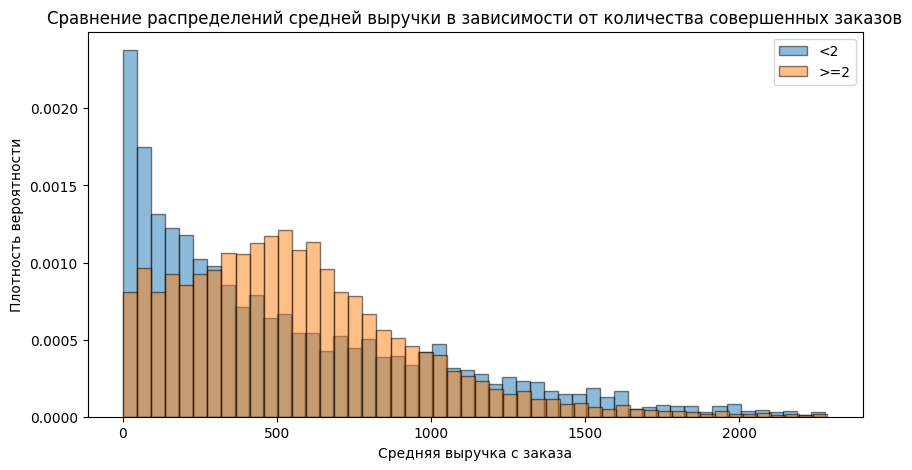

In [68]:
# Проводим фильтрацию по 99-му перцентилю 
filter_revenue = (user_profile['avg_revenue_rub'] <= user_profile['avg_revenue_rub'].quantile(0.99)) & (user_profile['avg_revenue_rub'] > 0)

filtered_profile = user_profile[filter_revenue]

plt.figure(figsize=(10,5))

for i in user_profile['is_two'].unique():
    filtered_profile.loc[filtered_profile['is_two'] == i, 'avg_revenue_rub'].plot(
        kind='hist',
        bins=50,
        alpha=0.5,
        edgecolor='black',
        density=True
    )

plt.title('Сравнение распределений средней выручки в зависимости от количества совершенных заказов')
plt.xlabel('Средняя выручка с заказа')
plt.ylabel('Плотность вероятности')
plt.legend(['<2', '>=2'])


Распределения существенно различаются:
- У пользователей, совершивших менее 2 заказов, средняя выручка сильно сконцентрирована в самом начале шкалы (преимущественно в диапазоне 0–45 руб.). В этой зоне наблюдается максимальная плотность вероятности (около 0.0023). Это говорит о том, что среди ушедших пользователей очень высока доля тех, кто купил самый дешевый билет и больше не вернулся. Далее распределение резко падает.
- У пользователей, совершивших 2 и более заказов, пик распределения смещен вправо — в диапазон примерно 365–635 руб. После этого диапазона также идет плавный спад.

Пользователи, совершившие 2+ заказа, имеют более высокий средний чек по всем своим заказам, чем пользователи с одним заказом. Среди не вернувшихся пользователей высока доля клиентов с очень дешёвым единственным заказом. 

***Примечание:*** на этом и следующих графиках отсечён верхний 1% значений (фильтрация по 99-му перцентилю), чтобы основная часть распределения была различима.

---
Далее сравним распределение по средней выручке с заказа в двух группах пользователей:
- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

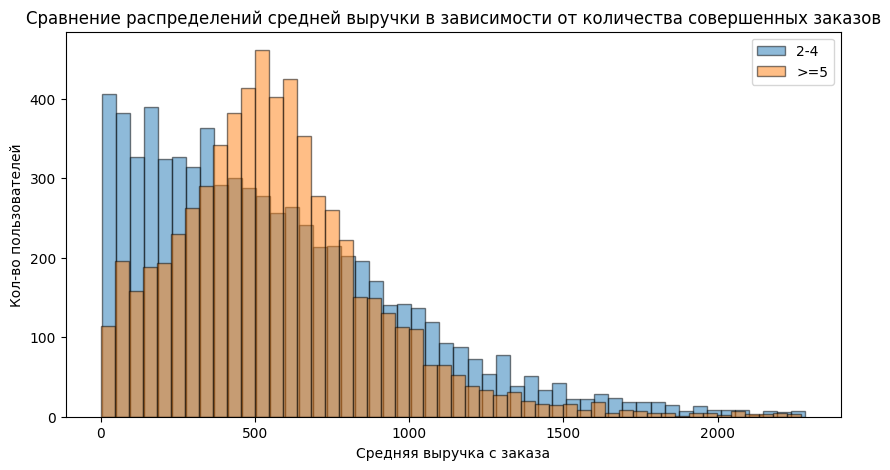

In [69]:
# Найдем пользователей, которые совершили от 5 заказов
more_4_orders = filtered_profile[filtered_profile['is_five'] == True] 

# Далее найдем пользователей, которые совершили от 2 до 4 заказов
in_range_2_to_4 = filtered_profile[(filtered_profile['is_two'] == True) & (filtered_profile['is_five'] == False)]

plt.figure(figsize=(10,5))

# Распределение для пользователей 2-4 заказа
in_range_2_to_4['avg_revenue_rub'].plot(
    kind='hist',
    bins=50,
    alpha=0.5,
    edgecolor='black',
)

# Распределение для пользователей >= 5
more_4_orders['avg_revenue_rub'].plot(
    kind='hist',
    bins=50,
    alpha=0.5,
    edgecolor='black',
)

plt.title('Сравнение распределений средней выручки в зависимости от количества совершенных заказов')
plt.xlabel('Средняя выручка с заказа')
plt.ylabel('Кол-во пользователей')
plt.legend(['2-4', '>=5'])


Распределения различаются.
- У пользователей с 2–4 заказами распределение имеет положительную ассиметрию. Пик приходится на дешевые заказы (до 100 руб.), но при этом количество людей, совершающих дорогие покупки (от 820 руб. и выше), в этой группе больше, чем в группе с 5+ заказами, следовательно, данная группа более склонна к дорогостоящим покупкам.
- У пользователей с 5 и более заказами пик смещен в средний ценовой сегмент — около 590 руб., а дорогие чеки встречаются реже, чем в первой группе.

Постоянные клиенты (5+ заказов) демонстрируют более стабильный и предсказуемый чек. Вторая группа более неоднородна, а значит и менее предсказуема.

---
Изучим распределение пользователей по среднему количеству билетов в заказе

Text(0, 0.5, 'Кол-во пользователей')

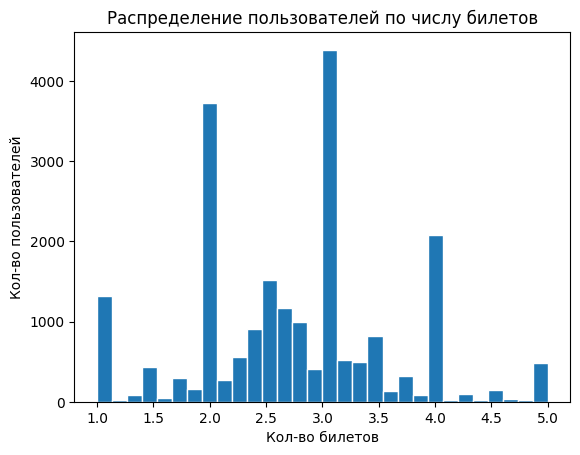

In [70]:
# Проводим фильтрацию по 99-му перцентилю 
filter_tickets = user_profile['avg_count_tickets'] <= user_profile['avg_count_tickets'].quantile(0.99)

filtered_profile = user_profile[filter_tickets]

filtered_profile['avg_count_tickets'].plot(
    kind='hist',
    bins=30,
    edgecolor='white'
)

plt.title('Распределение пользователей по числу билетов')
plt.xlabel('Кол-во билетов')
plt.ylabel('Кол-во пользователей')

Основные наблюдения:
- больше всего пользователей, которые в среднем совершают покупку 2 и 3 билетов. Их количество составляет около 3700 и 4500 чел. соответственно.
- Также существуют относительно большие сегменты пользователей: 1, 2.5 и 4 билетов. Количество пользователей в данных сегментах варьируется в диапазоне от 1300 - 2100.


Далее проведем сегментацию пользователей:
- от 1 до 2 билетов;
- от 2 до 3 билетов;
- от 3 до 5 билетов;
- от 5 и более билетов.

In [71]:

from_1_to_2 = user_profile[user_profile['avg_count_tickets'].between(1,2, inclusive='left')]
from_2_to_3 = user_profile[user_profile['avg_count_tickets'].between(2,3, inclusive='left')] 
from_3_to_5 = user_profile[user_profile['avg_count_tickets'].between(3,5, inclusive='left')] 
from_5_and_more = user_profile[user_profile['avg_count_tickets'] >= 5] 

In [72]:
df_grouped = from_1_to_2.groupby('is_two').size()

C:\Users\semen\AppData\Local\Temp\ipykernel_3176\1370242910.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0.5, 0, 'Вернулся (Да/Нет)')

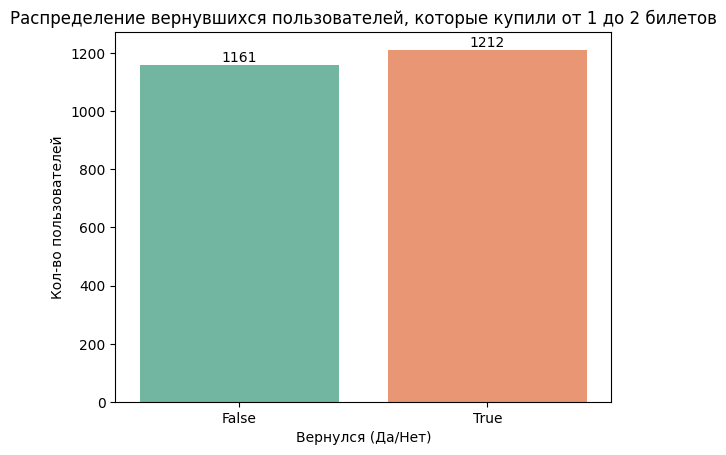

In [73]:
# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 1 до 2 билетов')
plt.ylabel('Кол-во пользователей')
plt.xlabel('Вернулся (Да/Нет)')

In [74]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 2373 чел. 
 Доля вернувшихся: 51% (1212 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_3176\2588201356.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0.5, 0, 'Вернулся (Да/Нет)')

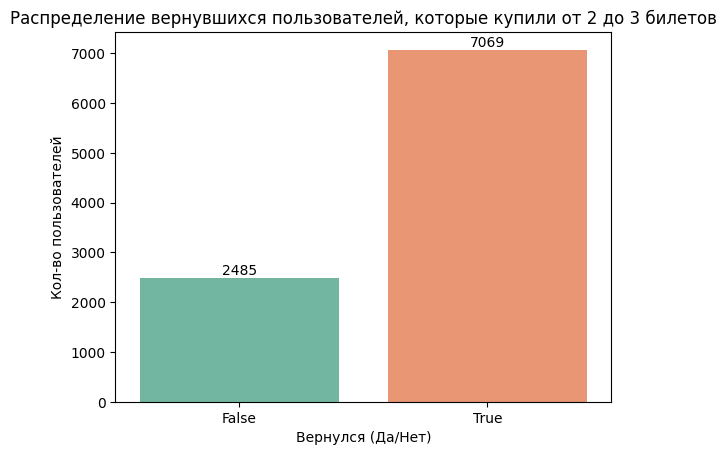

In [75]:
df_grouped = from_2_to_3.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 2 до 3 билетов')
plt.ylabel('Кол-во пользователей')
plt.xlabel('Вернулся (Да/Нет)')

In [76]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 9554 чел. 
 Доля вернувшихся: 74% (7069 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_3176\2672524481.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0.5, 0, 'Вернулся (Да/Нет)')

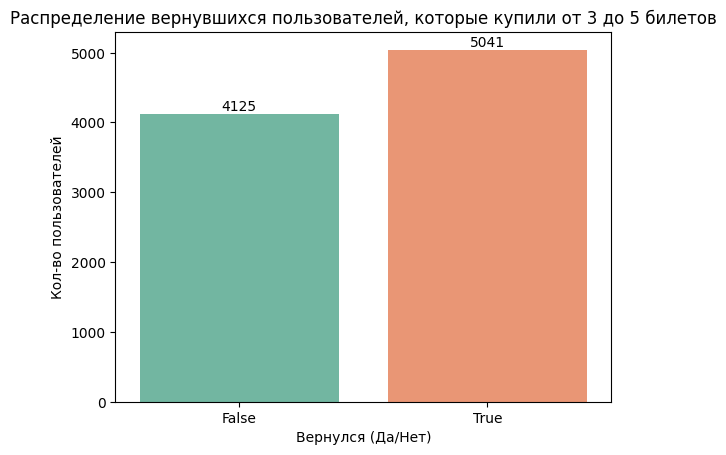

In [77]:
df_grouped = from_3_to_5.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 3 до 5 билетов')
plt.ylabel('Кол-во пользователей')
plt.xlabel('Вернулся (Да/Нет)')

In [78]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 9166 чел. 
 Доля вернувшихся: 55% (5041 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_3176\4173129227.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0.5, 0, 'Вернулся (Да/Нет)')

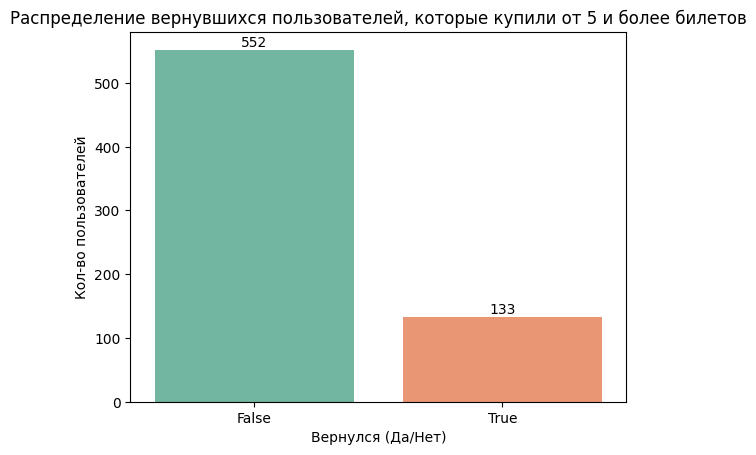

In [79]:
df_grouped = from_5_and_more.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])


plt.title('Распределение вернувшихся пользователей, которые купили от 5 и более билетов')
plt.ylabel('Кол-во пользователей')
plt.xlabel('Вернулся (Да/Нет)')

In [80]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 685 чел. 
 Доля вернувшихся: 19% (133 чел.)


Пользователи в каждом сегменте распределены неравномерно:
- В сегменте от 1 до 2 билетов: 2373 чел. с долей вернувшихся: 51% (1212 чел.)
- В сегменте от 2 до 3 билетов: 9554 чел. с долей вернувшихся: 74% (7069 чел.)
- В сегменте от 3 до 5 билетов: 9166 чел. с долей вернувшихся: 55% (5041 чел.)
- В сегменте от 5 билетов и более: 685 чел. с долей вернувшихся: 19% (133 чел.)

Как мы видим самый большой сегмент пользователей, которые купили от 2 включительно и 3  не включительно билетов, также он имеет самую большую долю вернувшихся клиентов, и как следствие постоянных клиентов, что говорит о хорошем уровне сервиса. Самый маленький сегмент - от 5 и более билетов, он аномально мал. 

Самый большой потенциал роста — в сегментах 1–2 билета и 3–5 билетов. У них достаточно большая аудитория, но доля возвратов (51% и 55%) значительно ниже, чем у группы 2–3 (74%). Маркетингу стоит направить усилия на удержание именно этих групп. Сегмент 5+ билетов не является приоритетным для массового удержания.

---
### Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучим временные параметры, связанные с первым заказом пользователей:
- день недели первой покупки;
- средний интервал между покупками пользователей с повторными заказами.

In [81]:
# Добавим новый столбец к профилю пользователя - номер дня недели
user_profile['week_number'] = user_profile['first_order_data'].map(lambda x: x.isoweekday())

Для экономии памяти, приведем данный столбец к типу `category`.

In [82]:
user_profile['week_number'] = user_profile['week_number'].astype('category')

Был добавлен новый столбец, в котором написан номер дня недели в нотации ISO. Рассмотрим распределение пользователей относительно этого номера.

Text(0, 0.5, 'Кол-во пользователей')

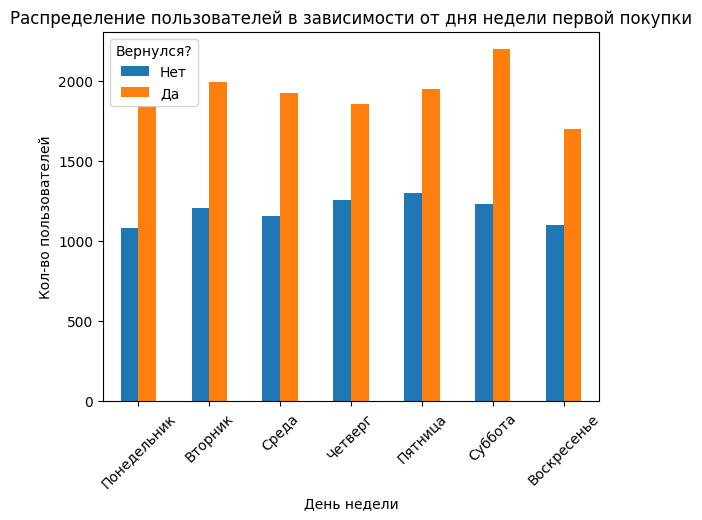

In [83]:
pivot_users = pd.pivot_table(
    user_profile,
    index='week_number',
    columns='is_two',
    values='first_order_data', # здесь можно взять любой не имеющий пропусков атрибут
    aggfunc='count'
)

pivot_users.rename(columns={True: 'Да', False: 'Нет'}, inplace=True)

ax = pivot_users.plot(
    kind='bar',
    rot=45
)

legend = ax.get_legend()
legend.set_title('Вернулся?')

plt.xticks(ticks=range(7), labels=['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье'])
plt.title('Распределение пользователей в зависимости от дня недели первой покупки')
plt.xlabel('День недели')
plt.ylabel('Кол-во пользователей')

In [84]:
pivot_users

is_two,Нет,Да
week_number,,
1,1080,1839
2,1206,1994
3,1154,1921
4,1257,1857
5,1298,1947
6,1229,2196
7,1099,1701


Из распределения видно, что:
- В понедельник первый заказ оформило - 2919 чел.
- Во вторник - 3200 чел.
- В среду - 3075 чел.
- В четверг - 3114 чел.
- В пятницу - 3245 чел.
- В субботу - 3425 чел.
- В воскресенье - 2800 чел.

Большинство людей совершили первый заказ в субботу, меньше всего в воскресенье, разница в пользователях составляет 625 чел.

Также:
- Больше всего вернувшихся пользователей в субботу (2196), что составляет 64% от числа пользователей в субботу(3425 чел.). 
- Наименьшее кол-во пользователей в воскресенье - 2800 чел, кол-во вернувшихся 1701 - 61%.
- Наименьшая доля вернувшихся пользователей приходится на четверг (1857 чел.) - 60%
- Разница между наибольшой и наименьшей долями составляет 4,5 п.п

**Из наблюдений можно сделать вывод, что день недели почти не влияет на вероятность возврата пользователя.**

Также был добавлен новый столбец типа category, который показывает день недели даты первой покупки пользователя в нотации ISO.

---
Рассчитаем среднее время между заказами для двух групп пользователей:
- совершившие 2–4 заказа;
- совершившие 5 и более заказов

Text(0, 0.5, 'Кол-во пользователей')

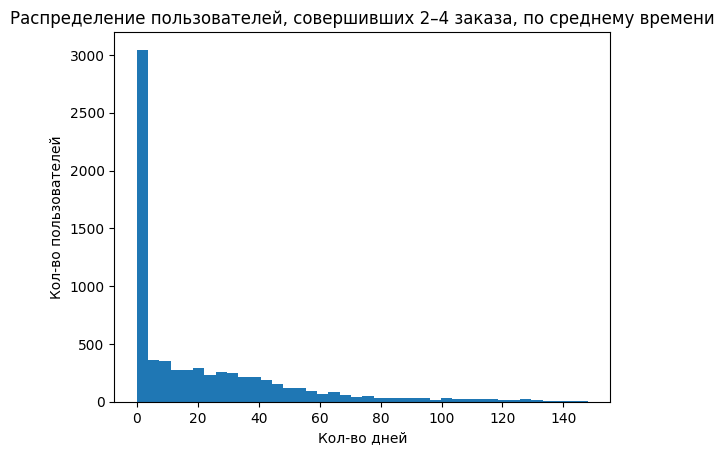

In [85]:
df_filtered = user_profile[(user_profile['is_two'] == True) & (user_profile['is_five'] == False)]['time_between_orders']

df_filtered.plot(
    kind='hist',
    bins=40
)

plt.title('Распределение пользователей, совершивших 2–4 заказа, по среднему времени')
plt.xlabel('Кол-во дней')
plt.ylabel('Кол-во пользователей')


In [86]:
print(f'Среднее время между заказами для пользователей, совершивших 2–4 заказа: {round(df_filtered.mean())} дней')
print(f'Медианное время: {round(df_filtered.median())} дней')
print(f'Самое частое время: {df_filtered.value_counts().index[0]} дней, которое встречалось {df_filtered.value_counts()[0]} раз')


Среднее время между заказами для пользователей, совершивших 2–4 заказа: 21 дней
Медианное время: 9 дней
Самое частое время: 0.0 дней, которое встречалось 2458 раз


Text(0, 0.5, 'Кол-во пользователей')

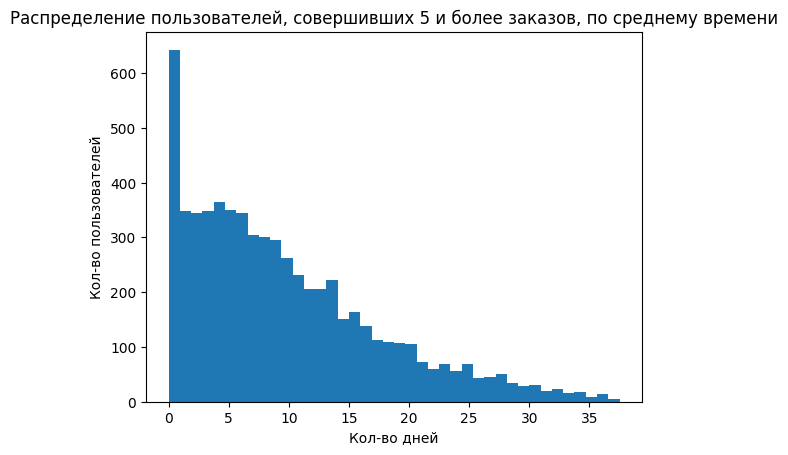

In [87]:
df_filtered = user_profile[user_profile['is_five'] == True]['time_between_orders']

df_filtered.plot(
    kind='hist',
    bins=40
)

plt.title('Распределение пользователей, совершивших 5 и более заказов, по среднему времени')
plt.xlabel('Кол-во дней')
plt.ylabel('Кол-во пользователей')

In [88]:
print(f'Среднее время между заказами для пользователей совершивших 5 и более заказов: {round(df_filtered.mean())} дней')
print(f'Медианное время: {round(df_filtered.median())} дней')
print(f'Самое частое время: {df_filtered.value_counts().index[0]} дней, которое встречалось {df_filtered.value_counts()[0]} раз')

Среднее время между заказами для пользователей совершивших 5 и более заказов: 10 дней
Медианное время: 8 дней
Самое частое время: 0.0 дней, которое встречалось 277 раз


Для обеих групп пользователей характерно совершение покупок в один день (мода = 0 дней), а медианный интервал между заказами составляет 8–9 дней.

Однако среднее время и форма распределения существенно различаются:
- У пользователей с 2–4 заказами ярко выражена правосторонняя асимметрия: при медиане в 9 дней среднее значение составляет 21 день. Это говорит о нестабильном поведении.
- У самых лояльных пользователей (5+ заказов) средний интервал почти в два раза меньше — 10 дней, а хвост распределения ограничивается 38 днями.

Пользователи, ставшие постоянными (5+ заказов), характеризуются значительно меньшим средним интервалом и меньшим разбросом. Это означает, что **короткий интервал коррелирует с переходом в категорию лояльных клиентов.**

---
### Корреляционный анализ количества покупок и признаков пользователя

Рассчитаем коэффициент корреляции phi_k между признаками профиля пользователя и числом заказов ( total_orders ).

Проверим, какое количество уникальных значений присутствует в колонках `first_region` и `first_service_name`.

In [89]:
for column in ['first_region', 'first_service_name']:
    print(f'{column}: {user_profile[column].nunique()}')

first_region: 81
first_service_name: 34


Количество значений не превышает 100, оставим без изменений. Интервальные колонки для подсчета:
- avg_revenue_rub 
- avg_count_tickets 
- time_between_orders
- total_orders

**Для анализа эти параметры (сырые даты) задействованы не будут**:
- first_order_data
- last_order_data

Вместо данных атрибутов создадим новую колонку `lifetime`, которая будет отображать длительность жизненного цикла (в днях) с момента первой покупки и до последней.

In [90]:
# Создадим новую колонку lifetime с понижением разрядности
user_profile['lifetime'] = pd.to_numeric((user_profile['last_order_data'] - user_profile['first_order_data']).dt.days, downcast='integer')

In [91]:
# Создадим список интервальных колонок
interval_columns = ['avg_revenue_rub', 'avg_count_tickets', 'time_between_orders', 'total_orders', 'lifetime']
# Все колонки, которые будут задействованы в поиске корреляции 
useful_columns = interval_columns + ['first_device_type', 'first_region', 'first_service_name', 'first_event_type_main', 'is_two', 'is_five']


In [92]:
correlation_matrix = user_profile[useful_columns].phik_matrix(interval_cols=interval_columns)

Визуализируем полученные результаты 

In [93]:
data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

Text(8.081597222222214, 0.5, 'Признаки профиля')

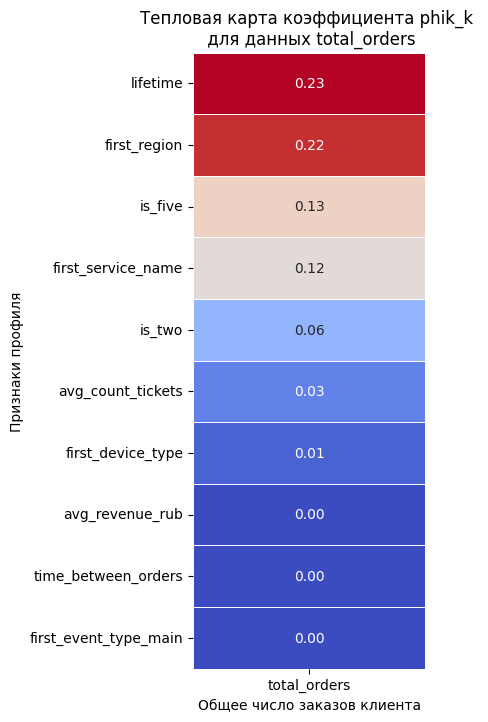

In [94]:
plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders')
plt.xlabel('Общее число заказов клиента')
plt.ylabel('Признаки профиля')

По полученным результатам можно сделать вывод:
- имеется 5 атрибутов, с которыми существует корреляция: регион, билетный оператор, жизненный цикл и параметры is_two и is_five. Наибольшая корреляция — с первым регионом (0.13), наименьшая — с is_two (0.03).
- Также имеется 5 параметров, у которых корреляции практически нет: средняя выручка, среднее число билетов, время между заказами, тип устройства и мероприятия.

Основная причина слабой связи по всей выборке — хвост из 218 высокоинтенсивных аккаунтов, дающих около половины заказов: он остаётся в данных и ухудшает зависимость.

In [95]:
# Создадим отфильтрованный профиль
columns = ['total_orders', 'avg_revenue_rub']
user_profile_filtered = user_profile
for column in columns:
    user_profile_filtered = user_profile_filtered[user_profile_filtered[column] <= user_profile_filtered[column].quantile(0.99)]

user_profile_filtered = user_profile_filtered[user_profile_filtered['avg_revenue_rub'] > 0]

**В моменте создания отфильтрованного профиля пользователя возникла проблема с фильтрацией по `time_between_orders`. Так как этот параметр имеет NaN значения, то любая фильтрация по этому полю будет работать некорректно.**

Для того чтобы посмотреть на реальную корреляцию **проведем сегментацию пользователей**:
- 1 заказ;
- от 2 до 4 заказов;
- от 5 и выше.

Во втором и третьем сегментах следует провести фильтрацию по `time_between_orders`. В этих сегментах NaN значения отсутствуют, все пропуски остались в первом сегменте.

In [96]:
filter_second_segment = (user_profile_filtered['total_orders'].isin([2,3,4])) & (user_profile_filtered['time_between_orders'] < user_profile_filtered['time_between_orders'].quantile(0.99) )
filter_third_segment = (user_profile_filtered['total_orders'] >= 5) & (user_profile_filtered['time_between_orders'] < user_profile_filtered['time_between_orders'].quantile(0.99) )

first_segment = user_profile_filtered[useful_columns][user_profile_filtered['total_orders'] == 1]
second_segment = user_profile_filtered[useful_columns][filter_second_segment]
third_segment = user_profile_filtered[useful_columns][filter_third_segment]

Также найдем размер каждого сегмента:

In [97]:
print(f'Размер первого сегмента: {first_segment.shape[0]} чел.')
print(f'Размер второго сегмента: {second_segment.shape[0]} чел.')
print(f'Размер третьего сегмента: {third_segment.shape[0]} чел.')

Размер первого сегмента: 8199 чел.
Размер второго сегмента: 6938 чел.
Размер третьего сегмента: 6077 чел.


Проведем корреляционный анализ для каждого сегмента:

In [98]:
correlation_matrix = first_segment.phik_matrix(interval_cols=interval_columns)

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable total_orders for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable lifetime for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


При расчете корреляционной матрицы для пользователей с одним заказом алгоритм phik выдал предупреждения и исключил из анализа целевую переменную total_orders, а также признаки is_two, is_five, time_between_orders и lifetime. Это ожидаемое поведение, а не ошибка кода. В данной группе все пользователи совершили ровно 1 заказ. Математически корреляция рассчитывается только для варьирующихся признаков. Поскольку целевая переменная не имеет разброса, **поиск зависимостей от нее в этом сегменте невозможен. Анализ корреляций имеет смысл только для сегментов с 2–4 и 5+ заказами.**

In [99]:
correlation_matrix = second_segment.phik_matrix(interval_cols=interval_columns)

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


При расчете матрицы корреляции для 2 сегмента **были удалены колонки** `is_two` и `is_five`, потому что в данном сегменте данные признаки приняли постоянные значения (для is_five везде False, для is_two везде True), поэтому дисперсия отсутствует.

Text(8.081597222222214, 0.5, 'Признаки профиля')

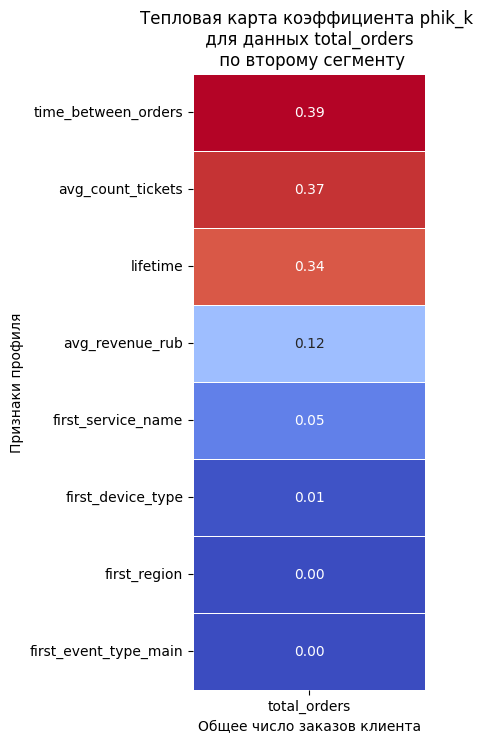

In [100]:
data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders \n по второму сегменту')
plt.xlabel('Общее число заказов клиента')
plt.ylabel('Признаки профиля')

Наиболее **сильные** взаимосвязи:
- lifetime 0.34
- avg_count_tickets 0.37
- time_between_orders 0.39

Также присутствует очень **слабая** связь с:
- first_service_name 0.06 
- avg_revenue_rub 0.11
- first_device_type 0.01

Связь avg_count_tickets с total_orders (0.37) может объясняться как поведением пользователей, так и эффектом усреднения: при большем числе заказов среднее число билетов сильнее концентрируется около общего среднего. Также с количеством заказов может увеличиваться параметр `lifetime`. Наибольшую корреляцию показывает параметр `time_between_orders`, который стоит дополнительно изучить, так как он зависит от поведения пользователя.

Построим матрицу корреляции для 3 сегмента:

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


Text(8.081597222222214, 0.5, 'Признаки профиля')

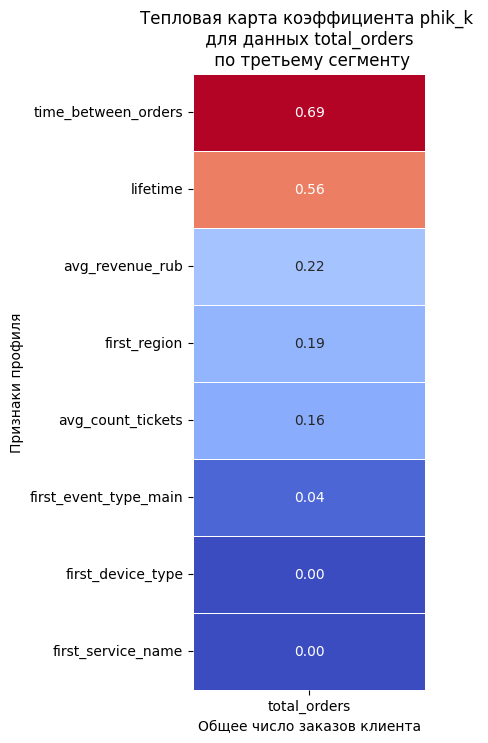

In [101]:
correlation_matrix = third_segment.phik_matrix(interval_cols=interval_columns)

data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders \n по третьему сегменту')
plt.xlabel('Общее число заказов клиента')
plt.ylabel('Признаки профиля')

Как и при построении матрицы для 2-го сегмента, **были удалены колонки** `is_two` и `is_five`, потому что в данном сегменте данные признаки приняли постоянные значения.

В данном сегменте корреляция **более сильная**, чем в прошлом сегменте:
- time_between_orders 0.70
- lifetime 0.56

**Слабая** связь:
- avg_revenue_rub: 0.22
- first_region 0.17
- avg_count_tickets 0.16
- first_service_name 0.05
- first_event_type_main 0.05

В данном сегменте параметр `time_between_orders` имеет наибольшую связь, на 0.31 больше, чем во 2 сегменте. Параметр `lifetime` вырос на 0.22. Среднее количество билетов упало на 0.21.

---
### Промежуточный вывод

При проведении корреляционного анализа колонки `total_orders`:
- Создана новая колонка `lifetime` (в днях),отображающая длительность жизненного цикла клиента (от первой до последней покупки).
- Проведен общий анализ профилей пользователей, при котором найдена слабая связь(0.13) с параметром `first_region`
- Проведена сегментация пользователей: 1 заказ, от 2 до 4 заказов, от 5 и выше. Размеры сегментов составили: 8199, 6938 и 6077 человек соответственно.

**Первый сегмент не был рассмотрен**, так как алгоритм phik исключил целевую переменную total_orders из-за отсутствия вариативности (у всех пользователей ровно 1 заказ).Во 2 и 3 сегментах из матрицы были удалены признаки is_two и is_five, так как они приняли постоянные значения и не имели разброса.

Связь с `total_orders` в разрезе сегментов:
- Во втором сегменте наиболее сильная связь с `time_between_orders` (0.39) и `avg_count_tickets` (0.37).
- В третьем сегменте - `time_between_orders` (0.70), и средняя связь с `lifetime` (0.56).

Стоит учитывать,  что данные ограничены 5 месяцами (июнь–октябрь 2024), поэтому параметр `total_orders` больше всего коррелирует с `time_between_orders`: чем больше заказов сделал пользователь, тем меньше у него должно быть `time_between_orders`. Средняя корреляция с lifetime объясняется тем же — для большого числа заказов нужен длительный период активности.

**Для точного определения причинно-следственной связи следует провести анализ переменной time_between_orders в 2 и 3 сегментах.**

---
## Подведём итоги
В ходе исследования проанализировали данные 21 778 пользователей Яндекс Афиши за период 01.06.2024 – 31.10.2024. Данные включали информацию о заказах, мероприятиях и особенностях оплаты. Акцент исследования был на том, чтобы найти взаимосвязи между повторным заказом и другими факторами: типом первого мероприятия, типом устройства, регионом проведения мероприятия, билетным оператором, днём недели, лайфтаймом, средним интервалом между покупками и общим количеством покупок.

### Информация о данных
Профиль пользователя сформирован по 274 605 заказам (после очистки). Ещё на этапе SQL-выгрузки были исключены мероприятия категории фильм и заказы с устройств, отличных от `mobile`/`desktop`, — из-за этого число уникальных пользователей сократилось с 22 000 до 21 933, а после очистки — до 21 778:
- Выручка заказов, оплаченных в тенге, переведена в рубли по дневному курсу за 2024 год.
- Найдены аномальные значения: отрицательная выручка (0.13% заказов), нулевая выручка (2% заказов), выбросы в числе заказов и интервалах между покупками.Невалидные транзакции (выручка ≤ 0), неполные дубликаты и аномальный пользователь удалены; фильтрация по 99-му перцентилю применялась только для визуализации и корреляционного анализа.
- Пропуски в days_since_prev (7.55%) не заполнялись — это первые заказы пользователей.

***Распределение пользователей по числу заказов:***
- 1 заказ — 38.2% пользователей;
- 2 и более заказа — 61.8%;
- 5 и более заказов — 29.2%.
Медианное число заказов на пользователя — 2.
Медианный средний чек клиента — 484 руб. , среднее число билетов в заказе — 2.8. У вернувшихся пользователей медианный интервал между заказами — 8 дней.

***Признаки первого заказа***
- Самый массовый сегмент по типу первого мероприятия — концерты: 44% пользователей.
- 83% пользователей совершили первый заказ с мобильного устройства.
- Топ-10 билетных операторов покрывают 90.1% пользователей. Самый массовый оператор — Билеты без проблем: у него наименьшая доля возвратов среди топ-10 (60.2%), но наибольшее абсолютное число вернувшихся — 3 018 чел.
- Топ-10 регионов покрывают 71.9% пользователей. Лидер по числу пользователей — Каменевский регион: 7 094 чел. (32.6%).

***Выручка и состав заказа***
- Пользователи, совершившие 2 и более заказа, имеют более высокий средний чек, чем пользователи с одним заказом.
- Пик распределения среднего чека по сегментам: 1 заказ — 0–45 руб.; 2–4 заказа — до 100 руб.; 5+ заказов — около 590 руб..
- Пользователи с 5+ заказами более предсказуемы по чеку; пользователи с 2–4 заказами чаще совершают дорогостоящие покупки.
- Крупнейшие сегменты по среднему числу билетов в заказе: 2–3 билета —  9 554 чел., доля возвратов 74% (7 069 чел.) ; 3–5 билетов — 9 166 чел., 55% (5 041 чел.).

***Временные характеристики***
- День недели первой покупки почти не влияет на вероятность возврата.
- Для групп 2–4 и 5+ заказов характерны покупки в один день: самое частое значение среднего интервала в обеих группах — 0 дней.

***Корреляционный анализ***
- Наиболее сильная связь с числом заказов (total_orders) — у среднего интервала между заказами (time_between_orders): phi_k = 0.39 в сегменте 2–4 заказа и 0.70 в сегменте 5+. При окне наблюдения в 5 месяцев большее число заказов означает меньший средний интервал между ними.

### Факторы, связанные с возвратом пользователя
***Известны при первом заказе:***
- регион и тип мероприятия. Выше среднего возвращаются начавшие с театра и выставок, ниже — со спорта. Среди регионов выделяются Шанырский (лучший) и Озернинский край с Малиновоярским округом (худшие).
- билетный оператор, тип устройства, день недели первой покупки — различия между сегментами минимальны.

***Известны только после нескольких заказов:***
- Среднее число билетов в заказе: чаще всего возвращаются те, кто покупает 2–3 билета; покупающие по 5 и более билетов почти не возвращаются.
- Средний чек: у вернувшихся пользователей он заметно выше, чем у совершивших один заказ. Среди не вернувшихся пользователей много клиентов с очень дешёвым единственным заказом.
- Интервал между заказами: постоянные клиенты покупают примерно вдвое чаще (в среднем раз в 10 дней против 21 дня у менее активных).
- Докупки в тот же день — типичное поведение обеих групп повторных покупателей.

### Рекомендации
- Провести программы удержания для сегментов по билетам 1–2 и 3–5.
- Провести углубленный анализ уровня сервиса в Озернинском крае и Малиновоярском округе и выяснить причины оттока
- Выяснить причины оттока по типу мероприятия спорт
- Создать предложения сразу после заказа.